# NIErnaya 2026 · Phase 2 — EDA, Preprocessing & Feature Engineering
**SDG 2 — Zero Hunger · Team DAV-26-046 "Pixel Pioneers"**

**Question we investigate:** *Does high agricultural output translate into better child nutrition? Where do high production and poor nutrition coexist, and what else explains the gap?*

**Plan of the notebook**
1. Load and understand the data
2. Cleaning: missing values, duplicates, outliers, inconsistent names, with a before/after log
3. Linking datasets: matching ~700 districts across sources
4. Feature engineering
5. Exploratory data analysis: distributions, regional disparity, correlations, statistical tests
6. Preprocessing for modelling: imputation, transformation, scaling, feature selection
7. PCA
8. Insights and limitations

All paths are relative: run this notebook from the folder that holds `data/` and `helpers.py`.

In [1]:
import warnings, re, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LassoCV
from sklearn.model_selection import cross_val_score, KFold
import statsmodels.api as sm
from helpers import norm_state, norm_dist, match_districts

warnings.filterwarnings("ignore")
RAW, OUT, FIG = Path("data/raw"), Path("data/cleaned"), Path("figures")
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

# consistent look
mpl.rcParams.update({"figure.dpi":110,"savefig.dpi":150,"axes.spines.top":False,"axes.spines.right":False,
                     "axes.titleweight":"bold","axes.titlesize":12,"axes.labelsize":10,"font.size":10})
C = {"main":"#1f6f8b","accent":"#e4572e","good":"#2a9d8f","grey":"#8d99ae","dark":"#22223b"}
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG/f"{name}.png", bbox_inches="tight"); plt.show()

LOG = []   # cleaning log: every change we make is recorded here
def log(dataset, issue, found, action, after=""):
    LOG.append(dict(dataset=dataset, issue=issue, found=found, action=action, after=after))

## 1. Load and understand the data
| Source | What it is | Level |
|---|---|---|
| NFHS-5 (2019-21) | Child nutrition, women's health, household conditions | District (706) |
| UPAG district food grains | Area, production, yield by crop and year (2015-16 to 2024-25) | District |
| District crop production 1997-2022 | Rice, wheat, maize, sugarcane | District |
| Agmarknet | Monthly wholesale prices and arrivals | State |
| FCI procurement | Rice and wheat procured by state | State |

In [2]:
nf_raw = pd.read_csv(RAW/"02_nfhs5_district_nutrition_health.csv", dtype=str)
crop_raw = pd.read_csv(RAW/"01_district_crop_production.csv")
upag_raw = pd.read_csv(RAW/"upag_district_foodgrains.csv.gz")
ag_raw = pd.read_csv(RAW/"agmarknet_state_monthly.csv.gz")
fci_raw = pd.read_csv(RAW/"upag_fci_procurement.csv.gz")
overview = pd.DataFrame({
 "dataset":["NFHS-5 district","Crop production 1997-2022","UPAG district food grains","Agmarknet state monthly","FCI procurement"],
 "rows":[len(nf_raw),len(crop_raw),len(upag_raw),len(ag_raw),len(fci_raw)],
 "columns":[nf_raw.shape[1],crop_raw.shape[1],upag_raw.shape[1],ag_raw.shape[1],fci_raw.shape[1]]})
overview

,dataset,rows,columns
0,NFHS-5 district,706,109
1,Crop production 1997-2022,74242,8
2,UPAG district food grains,719427,7
3,Agmarknet state monthly,203798,7
4,FCI procurement,363,8


## 2. Data cleaning
### 2.1 NFHS-5: suppressed values, small-sample flags, inconsistent names
NFHS stores every number as text. Two special markers appear:
* `*` means the estimate is **suppressed** (too few cases). We convert it to a missing value. It is not a zero.
* `(12.3)` means the estimate rests on a **small sample** (25-49 cases). The number is usable, so we keep it, strip the brackets and record how many such cells each district has.

In [3]:
nf = nf_raw.rename(columns={"District Names":"district","State/UT":"state"}).copy()
for c in ["district","state"]:
    nf[c] = nf[c].str.strip()
nf["state"] = (nf["state"].replace({"Maharastra":"Maharashtra","NCT of Delhi":"Delhi"})
               .str.replace("&","and",regex=False))
log("NFHS-5","inconsistent state names / stray whitespace",
    f"{(nf_raw['State/UT']!=nf_raw['State/UT'].str.strip()).sum()} padded + 'Maharastra' typo","stripped, typo fixed, '&' -> 'and'")
nf["state_k"] = nf["state"].map(norm_state)

val_cols = [c for c in nf_raw.columns if c not in ["District Names","State/UT"]]
s = nf_raw[val_cols].apply(lambda c: c.str.strip())
is_star  = s.eq("*")
is_brack = s.apply(lambda c: c.str.fullmatch(r"\(.*\)"))
num = s.apply(lambda c: pd.to_numeric(c.str.replace(r"[()]","",regex=True).replace("*",np.nan), errors="coerce"))
n_cells = s.size
log("NFHS-5","suppressed '*' values", f"{int(is_star.sum().sum()):,} cells ({is_star.sum().sum()/n_cells:.1%})",
    "converted to NaN (not zero)", f"{int(num.isna().sum().sum()):,} NaN")
log("NFHS-5","bracketed small-sample values", f"{int(is_brack.sum().sum()):,} cells", "brackets removed, value kept, count stored per district")
log("NFHS-5","numeric stored as text", f"{len(val_cols)} columns", "converted to float")

nf_full = pd.concat([nf[["state","district","state_k"]], num], axis=1)
nf_full["n_small_sample_cells"] = is_brack.sum(axis=1).values
nf_full["n_suppressed_cells"]  = is_star.sum(axis=1).values

# duplicates
d_key = nf_full.duplicated(["state","district"]).sum()
d_name = nf_full.duplicated(["district"], keep=False).sum()
log("NFHS-5","duplicate (state, district) rows", str(d_key), "none to remove")
log("NFHS-5","same district name in different states", f"{d_name} rows (e.g. Aurangabad, Bilaspur)", "kept: they are different districts; always join on (state, district)")

# range validation
pct_cols = [c for c in val_cols if c.strip().endswith("(%)")]
bad = {c: int(((num[c]<0)|(num[c]>100)).sum()) for c in pct_cols}
bad = {k:v for k,v in bad.items() if v}
log("NFHS-5","percent columns outside 0-100", str(sum(bad.values())), "none to fix" if not bad else "set to NaN")
print("NFHS rows, cols:", nf_full.shape, "| duplicates (state,district):", d_key, "| out-of-range % cells:", sum(bad.values()))

NFHS rows, cols: (706, 112) | duplicates (state,district): 0 | out-of-range % cells: 0


In [4]:
# short names for the indicators we use (checked by keyword so a wrong position would fail loudly)
SHORT = {
 "Children under 5 years who are stunted":"stunting", "Children under 5 years who are wasted":"wasting",
 "Children under 5 years who are severely wasted":"severe_wasting", "Children under 5 years who are underweight":"underweight",
 "Children age 6-59 months who are anaemic":"child_anaemia",
 "Women (age 15-49 years) whose Body Mass Index (BMI) is below normal":"women_low_bmi",
 "All women age 15-49 years who are anaemic":"women_anaemia",
 "Total children age 6-23 months receiving an adequate diet":"diet_adequate",
 "Children under age 6 months exclusively breastfed":"excl_breastfed",
 "Women (age 15-49)  with 10 or more years of schooling":"women_10yr_school",
 "Women (age 15-49) who are literate":"women_literate",
 "Population living in households that use an improved sanitation facility":"sanitation",
 "Households using clean fuel for cooking":"clean_fuel",
 "Population living in households with electricity":"electricity",
 "Population living in households with an improved drinking-water source":"drinking_water",
 "Institutional births (in the 5 years before the survey)":"institutional_births",
 "Children age 12-23 months fully vaccinated based on information from either":"full_vaccination",
 "Mothers who consumed iron folic acid for 100 days":"ifa_100d",
 "Mothers who had at least 4 antenatal care visits":"anc4",
 "Women age 20-24 years married before age 18":"early_marriage",
 "Households with any usual member covered under a health insurance":"health_insurance",
 "Sex ratio of the total population":"sex_ratio",
 "Population below age 15 years":"pop_below15",
 "Prevalence of diarrhoea in the 2 weeks":"diarrhoea",
}
rename = {}
for col in val_cols:
    for key, short in SHORT.items():
        if col.startswith(key) and short not in rename.values():
            rename[col] = short; break
assert len(rename) == len(SHORT), set(SHORT.values()) - set(rename.values())
nfs = nf_full.rename(columns=rename)
KEY = list(SHORT.values())
miss = (nfs[KEY].isna().mean()*100).round(1).sort_values(ascending=False)
print("Missing % in the indicators we use:\n", miss.to_string())

Missing % in the indicators we use:
 excl_breastfed          37.0
full_vaccination         1.8
diet_adequate            0.1
stunting                 0.0
underweight              0.0
child_anaemia            0.0
severe_wasting           0.0
wasting                  0.0
women_anaemia            0.0
women_low_bmi            0.0
women_literate           0.0
women_10yr_school        0.0
clean_fuel               0.0
electricity              0.0
drinking_water           0.0
sanitation               0.0
institutional_births     0.0
ifa_100d                 0.0
anc4                     0.0
early_marriage           0.0
health_insurance         0.0
sex_ratio                0.0
pop_below15              0.0
diarrhoea                0.0


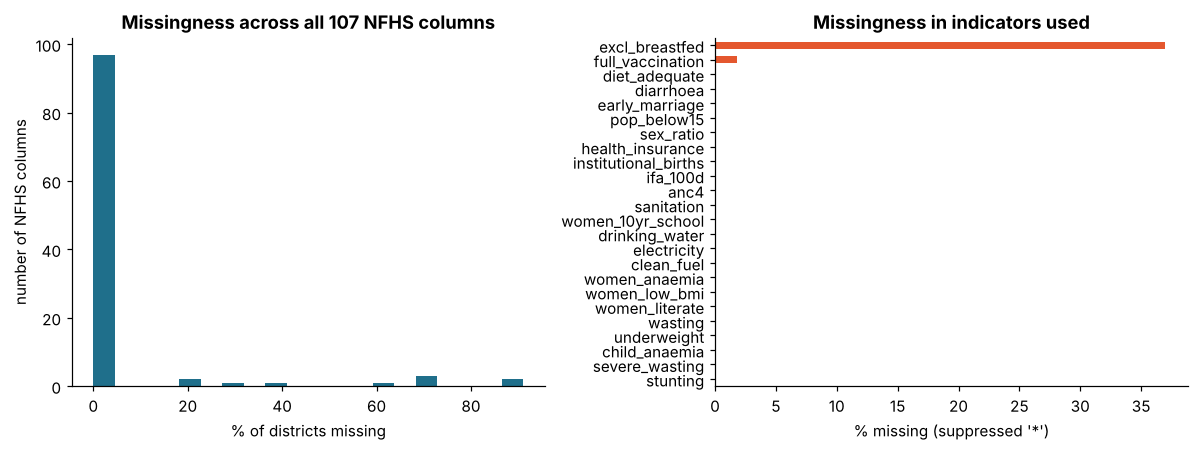

Columns with >30% missing: 8 | with any missing: 29


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
allmiss = (num.isna().mean()*100).sort_values(ascending=False)
ax[0].hist(allmiss, bins=20, color=C["main"]); ax[0].set_xlabel("% of districts missing"); ax[0].set_ylabel("number of NFHS columns")
ax[0].set_title("Missingness across all 107 NFHS columns")
miss.sort_values().plot.barh(ax=ax[1], color=C["accent"]); ax[1].set_xlabel("% missing (suppressed '*')"); ax[1].set_title("Missingness in indicators used")
save(fig, "01_missingness")
print("Columns with >30% missing:", int((allmiss>30).sum()), "| with any missing:", int((allmiss>0).sum()))

**Reading:** most columns are complete, but a few clinical indicators (blood sugar, cancer screening, etc.) have heavy suppression. We use only the nutrition, diet, education, sanitation and care indicators above; missingness there is very low except **exclusive breastfeeding** (37% suppressed), which we leave out of the modelling. Imputation therefore will not drive the results.

### 2.2 Crop production 1997-2022: impossible yields
Yield is tonnes per hectare. Some rows have tiny areas and absurd yields (e.g. maize 1,494 t/ha). We apply **agronomic ceilings** (physically possible maximum for each crop) and treat anything above as a data-entry error. These become missing, not deleted rows, so area totals elsewhere stay traceable.

In [6]:
crop = crop_raw.copy()
for c in ["State_Name","District_Name","Season","Crop"]:
    crop[c] = crop[c].str.strip()
dups = crop.duplicated().sum(); dkeys = crop.duplicated(["State_Name","District_Name","Crop_Year","Season","Crop"]).sum()
log("Crop 1997-2022","duplicate rows / duplicate keys", f"{dups} / {dkeys}", "none to remove")
log("Crop 1997-2022","missing values", str(int(crop.isna().sum().sum())), "none to fill")
CEIL = {"Rice":12, "Wheat":9, "Maize":15, "Sugarcane":200}      # t/ha, generous physical ceilings
crop["yield_calc"] = crop.Production/crop.Area.replace(0,np.nan)
before = crop.groupby("Crop").Yield.describe()[["max"]].rename(columns={"max":"max_yield_before"})
crop["bad_ceiling"] = crop.apply(lambda r: r.Yield > CEIL[r.Crop], axis=1)
crop["zero_area_or_prod"] = (crop.Area<=0)|(crop.Production<=0)
log("Crop 1997-2022","yield above agronomic ceiling", f"{int(crop.bad_ceiling.sum())} rows ({crop.bad_ceiling.mean():.2%})","yield/production/area set to NaN")
log("Crop 1997-2022","zero area or zero production", f"{int(crop.zero_area_or_prod.sum())} rows","yield set to NaN (not a real yield)")
crop_clean = crop.copy()
mask = crop_clean.bad_ceiling | crop_clean.zero_area_or_prod
crop_clean.loc[mask, ["Area","Production","Yield"]] = np.nan
after = crop_clean.groupby("Crop").Yield.describe()[["max"]].rename(columns={"max":"max_yield_after"})
print(before.join(after).round(2)); print("rows affected:", int(mask.sum()), "of", len(crop))

           max_yield_before  max_yield_after
Crop                                        
Maize               1494.00            15.00
Rice                 223.73            10.51
Sugarcane           2247.53           188.41
Wheat                  7.46             7.46
rows affected: 56 of 74242


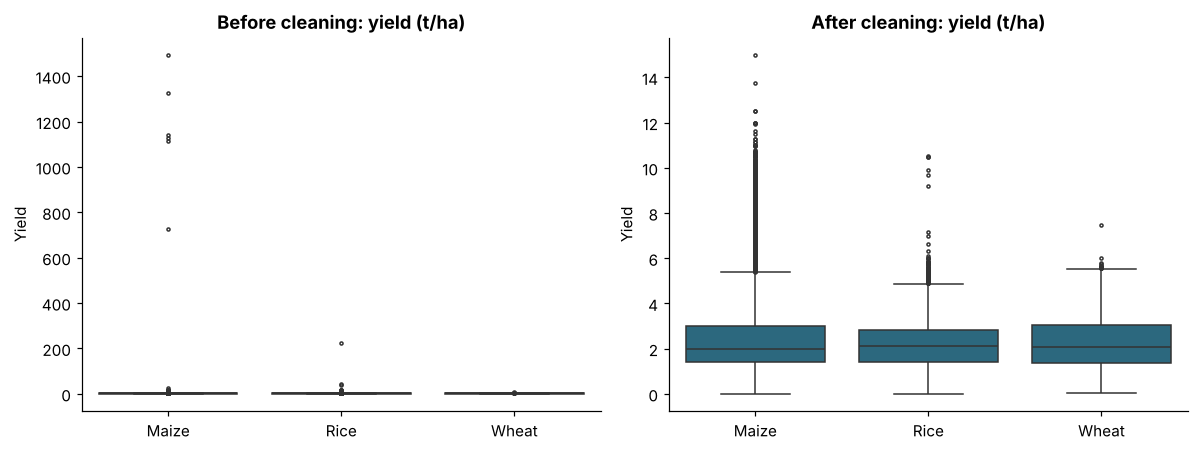

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharey=False)
for a, (d, t) in zip(ax, [(crop, "Before cleaning"), (crop_clean, "After cleaning")]):
    dd = d[d.Crop != "Sugarcane"]
    sns.boxplot(data=dd, x="Crop", y="Yield", color=C["main"], ax=a, fliersize=2); a.set_title(f"{t}: yield (t/ha)"); a.set_xlabel("")
save(fig, "02_crop_yield_outliers_before_after")

### 2.3 UPAG district food grains
Rows are district × crop × season × year. The `Total` season already adds Kharif, Rabi and Summer, so we use `Total` only. Adding the seasons as well would double count. Subtotals (Cereals, Total Pulses, Total Food Grains) are kept as separate crops and never summed with their parts.

In [8]:
up = upag_raw.copy()
for c in ["State","District","Crop","Season"]:
    up[c] = up[c].str.strip()
up = up[up.Season=="Total"]
dk = up.duplicated(["State","District","Crop","Crop Year","Metric"]).sum()
up_w = up.pivot(index=["State","District","Crop","Crop Year"], columns="Metric", values="Value").reset_index()
log("UPAG food grains","duplicate keys after selecting Season=Total", str(dk), "none")
na_before = up_w[["Area","Production","Yield"]].isna().sum().to_dict()
log("UPAG food grains","blank values", str(na_before), "kept as NaN; yield recomputed as production/area")
up_w["yield_kg_ha"] = up_w.Production/up_w.Area.replace(0,np.nan)*1000      # lakh tonnes / lakh ha -> kg/ha
mism = ((up_w.yield_kg_ha - up_w.Yield).abs()/up_w.Yield.replace(0,np.nan) > 0.10).sum()
log("UPAG food grains","reported yield differs >10% from production/area", f"{int(mism):,} rows (mostly rounding: production is published to 0.01 lakh tonnes)", "use recomputed yield")
UCEIL = {"Rice":10000,"Wheat":8000,"Maize":12000,"Cereals":10000,"Total Food Grains":9000,"Total Pulses":4000}
bad_u = up_w.apply(lambda r: r.yield_kg_ha > UCEIL.get(r.Crop, 12000), axis=1)
log("UPAG food grains","yield above agronomic ceiling", str(int(bad_u.sum())), "set to NaN")
up_w.loc[bad_u, ["Area","Production","yield_kg_ha"]] = np.nan
up_w["year0"] = up_w["Crop Year"].str[:4].astype(int)
print("district-crop-year rows:", len(up_w), "| districts:", up_w.groupby(["State","District"]).ngroups, "| blanks:", na_before, "| impossible yields removed:", int(bad_u.sum()))

district-crop-year rows: 96993 | districts: 751 | blanks: {'Area': 1, 'Production': 164, 'Yield': 165} | impossible yields removed: 56


## 3. Linking datasets: matching districts
Spellings and boundaries differ across sources (Ballari/Bellary, Purbi/Purba Champaran, new districts created after 2019). We match **within the same state** in three steps: exact normalised name, then known renames, then fuzzy match (similarity >= 0.84 and clearly better than the runner-up). Each NFHS district can take only one source district. Anything else stays unmatched. We never guess.

In [9]:
upd = up_w[["State","District"]].drop_duplicates().copy()
upd["state_k"] = upd.State.map(norm_state); upd["dist_raw"] = upd.District
m_up = match_districts(upd, nfs)
cd = crop_clean[["State_Name","District_Name"]].drop_duplicates().copy()
cd["state_k"] = cd.State_Name.map(norm_state); cd["dist_raw"] = cd.District_Name
m_cr = match_districts(cd, nfs)
cov = lambda m: len(set(zip(m.state_k[m.nfhs_district.notna()], m.nfhs_district.dropna())))
summ = pd.DataFrame({"source":["UPAG food grains","Crop 1997-2022"],
    "source_districts":[len(m_up),len(m_cr)],
    "exact":[(m_up.method=="exact").sum(),(m_cr.method=="exact").sum()],
    "fuzzy":[(m_up.method=="fuzzy").sum(),(m_cr.method=="fuzzy").sum()],
    "unmatched":[m_up.nfhs_district.isna().sum(),m_cr.nfhs_district.isna().sum()],
    "NFHS districts covered (of 706)":[cov(m_up),cov(m_cr)]})
log("Linking","district name mismatch UPAG -> NFHS", f"{int(summ.unmatched[0])} of {len(m_up)} UPAG districts unmatched (mostly districts created after 2019)", "fuzzy match within state; rest left unmatched")
summ

,source,source_districts,exact,fuzzy,unmatched,NFHS districts covered (of 706)
0,UPAG food grains,751,644,19,88,663
1,Crop 1997-2022,739,643,19,77,662


In [10]:
m_up.to_csv(OUT/"district_match_table_upag.csv", index=False)
m_up[m_up.method=="fuzzy"][["state_k","dist_raw","nfhs_district","score"]].reset_index(drop=True)

,state_k,dist_raw,nfhs_district,score
0,andamanandnicobarislands,South Andamans,South Andaman,0.960
1,andhrapradesh,Sri Potti Sriramulu Nellore,Sri Potti Sriramulu Nello,0.957
2,assam,Marigaon,Morigaon,0.875
3,bihar,Purbi Champaran,Purba Champaran,0.929
4,chhattisgarh,Kondagaon,Kodagaon,0.941
5,gujarat,Arvalli,Aravali,0.857
6,gujarat,Chhotaudepur,Chhota Udaipur,0.880
7,himachalpradesh,Lahaul And Spiti,Lahul & Spiti,0.963
8,jharkhand,Koderma,Kodarma,0.857
9,jharkhand,Sahebganj,Sahibganj,0.889


The fuzzy matches above are spelling variants of the same district (e.g. *Purbi/Purba Champaran*, *Haridwar/Hardwar*). The full match table is saved so a reviewer can audit every link.

## 4. Feature engineering
**Agriculture features** (district, averaged over **2017-18 to 2021-22**, the five years around NFHS-5's 2019-21 fieldwork):
* area, production, yield for food grains, cereals, pulses, rice, wheat, maize and millets
* `pulse_share`: share of pulses in food-grain production (protein availability proxy)
* `crop_diversity`: Shannon index across rice, wheat, maize, millets and pulses area
* `yield_growth`: yearly % change in food-grain yield (2015-16 to 2021-22)
* `prod_instability`: coefficient of variation of production

**Nutrition features**
* `cmi`: *Child Malnutrition Index* = mean z-score of stunting, wasting and underweight (higher = worse)
* PCA-based index in section 7 as a cross-check

**State context**: Rice and wheat price volatility (Agmarknet) and FCI procurement.

In [11]:
WIN = [f"{y}-{str(y+1)[-2:]}" for y in range(2017, 2022)]       # 2017-18 .. 2021-22
TREND = [f"{y}-{str(y+1)[-2:]}" for y in range(2015, 2022)]     # 2015-16 .. 2021-22
CROPS = {"Total Food Grains":"fg","Cereals":"cer","Total Pulses":"pul","Rice":"rice","Wheat":"wheat","Maize":"maize","Nutri/Coarse Cereals":"mil"}
w = up_w[up_w.Crop.isin(CROPS) & up_w["Crop Year"].isin(WIN)]
agg = (w.groupby(["State","District","Crop"])
        .agg(area=("Area","mean"), prod=("Production","mean"), n_years=("Production","count"),
             sp=("Production","sum"), sa=("Area", lambda s: s[w.loc[s.index,"Production"].notna()].sum())).reset_index())
agg["yield"] = agg.sp/agg.sa.replace(0,np.nan)*1000
agg = agg[agg.n_years>=3]                          # need at least 3 of 5 years
# production is published in units of 0.01 lakh tonnes, so crop-level yields are unreliable when the crop covers < 5,000 ha (0.05 lakh ha)
small = (agg.Crop!="Total Food Grains") & (agg.area<0.05)
log("UPAG food grains","crop-level yield on tiny areas (<5,000 ha)", f"{int(small.sum())} district-crop cells", "yield set to NaN (rounding makes it unreliable)")
agg.loc[small,"yield"] = np.nan
agri = agg.pivot(index=["State","District"], columns="Crop", values=["area","prod","yield"])
agri.columns = [f"{CROPS[c]}_{k}" for k,c in agri.columns]; agri = agri.reset_index()
# derived
agri["pulse_share"] = agri.pul_prod/agri.fg_prod
parts = agri[["rice_area","wheat_area","maize_area","mil_area","pul_area"]].fillna(0)
p = parts.div(parts.sum(axis=1).replace(0,np.nan), axis=0)
agri["crop_diversity"] = -(p*np.log(p.replace(0,np.nan))).sum(axis=1)
# growth and instability from 2015-16..2021-22
t = up_w[(up_w.Crop=="Total Food Grains")&up_w["Crop Year"].isin(TREND)].dropna(subset=["yield_kg_ha","Production"])
def slope(g):
    if len(g)<5: return np.nan
    return np.polyfit(g.year0, np.log(g.yield_kg_ha), 1)[0]*100
def cv(g): return g.Production.std()/g.Production.mean()*100 if len(g)>=5 else np.nan
gr = t.groupby(["State","District"]).apply(lambda g: pd.Series({"yield_growth":slope(g),"prod_instability":cv(g)})).reset_index()
agri = agri.merge(gr, on=["State","District"], how="left")
agri["state_k"] = agri.State.map(norm_state)
agri = agri.merge(m_up[["state_k","dist_raw","nfhs_district"]].rename(columns={"dist_raw":"District"}), on=["state_k","District"], how="left")
print("agri districts:", len(agri), "| matched to NFHS:", agri.nfhs_district.notna().sum())
agri.describe().T[["count","mean","50%","max"]].round(2).head(30)

agri districts: 697 | matched to NFHS: 653


,count,mean,50%,max
cer_area,697.0,1.51,1.18,9.53
maize_area,641.0,0.15,0.03,3.40
mil_area,672.0,0.36,0.09,9.39
rice_area,653.0,0.73,0.45,5.94
fg_area,697.0,1.92,1.42,12.06
pul_area,660.0,0.43,0.10,7.87
wheat_area,528.0,0.64,0.30,3.34
cer_prod,697.0,4.41,2.87,28.78
maize_prod,641.0,0.52,0.07,14.08
mil_prod,672.0,0.78,0.19,14.26


In [12]:
# state-level context: price volatility of a staple basket
BASKET = ["Rice","Wheat","Maize","Paddy(Common)","Bengal Gram(Gram)(Whole)","Red gram/Arhar/Tur(whole)","Green Gram(Moong)(Whole)",
          "Black Gram(Urd Beans)(Whole)","Potato","Onion"]
ag = ag_raw[ag_raw.commodity.isin(BASKET) & (ag_raw.month>="2019-01") & (ag_raw.month<="2022-12")].copy()
ag["state_k"] = ag.state.map(norm_state)
log("Agmarknet","blank price rows (staple basket, 2019-22)", f"{ag.price_rs_qtl.isna().sum()} of {len(ag)} ({ag.price_rs_qtl.isna().mean():.0%})",
    "kept as NaN; a state-commodity needs >=24 valid months to get a volatility figure")
def vol(g):
    g = g.sort_values("month").dropna(subset=["price_rs_qtl"])
    if len(g)<24: return np.nan
    return np.log(g.price_rs_qtl).diff().dropna().std()*100       # std of monthly % price change
pv = ag.groupby(["state_k","commodity"]).apply(vol).rename("vol").reset_index()
price_state = pv.groupby("state_k").agg(price_vol_basket=("vol","mean"), n_commodities=("vol","count")).reset_index()
price_state.loc[price_state.n_commodities<3, "price_vol_basket"] = np.nan          # need >=3 commodities
fc = fci_raw[fci_raw.years.isin(["2019-20","2020-21","2021-22"]) & (fci_raw.statename!="All India")].copy()
fc["state_k"] = fc.statename.map(norm_state)
fci = fc.groupby(["state_k","years"]).valuess.sum().groupby("state_k").mean().rename("fci_procured_lmt").reset_index()
state_ctx = price_state.merge(fci, on="state_k", how="outer")
print(state_ctx.round(2).head(8)); print("states with price-volatility figure:", state_ctx.price_vol_basket.notna().sum(), "| with FCI data:", state_ctx.fci_procured_lmt.notna().sum())

                    state_k  price_vol_basket  n_commodities  fci_procured_lmt
0  andamanandnicobarislands               NaN              0               NaN
1             andhrapradesh             13.84              5             46.33
2          arunachalpradesh               NaN              0               NaN
3                     assam               NaN              0              2.14
4                     bihar               NaN              0             23.81
5                chandigarh               NaN              1              0.31
6              chhattisgarh             19.41              8             54.47
7                     delhi             17.36              4              0.03
states with price-volatility figure: 18 | with FCI data: 25


### 4.1 Build the district master table
One row per NFHS district, with nutrition outcomes, agriculture features and state context.

In [13]:
a = agri[agri.nfhs_district.notna()].drop(columns=["State","District"]).rename(columns={"nfhs_district":"district"})
master = nfs.merge(a, on=["state_k","district"], how="left").merge(state_ctx, on="state_k", how="left")
master["has_agri"] = master.fg_prod.notna()
# Child Malnutrition Index: mean z-score of the three anthropometric failures
Z = ["stunting","wasting","underweight"]
zs = (master[Z]-master[Z].mean())/master[Z].std()
master["cmi"] = zs.mean(axis=1, skipna=False)
master["log_fg_prod"] = np.log1p(master.fg_prod); master["log_fg_area"] = np.log1p(master.fg_area)
sample = master[master.has_agri & master.cmi.notna()].copy()
log("Linking","NFHS districts with usable agriculture data", f"{len(sample)} of {len(master)}","analysis sample (others lack a matching district or have <3 years of data)")
print(f"master: {master.shape} | analysis sample: {len(sample)} districts in {sample.state.nunique()} states")
print("states in sample:", sample.state.nunique(), "| districts per state (median):", int(sample.groupby('state').size().median()))

master: (706, 144) | analysis sample: 653 districts in 32 states
states in sample: 32 | districts per state (median): 19


## 5. Exploratory data analysis
### 5.1 What does child malnutrition look like?

                count  mean   std   min   50%   max  skew
stunting        653.0  33.5   8.5  13.2  32.8  59.0   0.2
wasting         653.0  18.6   6.3   5.9  18.1  38.9   0.4
underweight     653.0  29.7   9.6   8.1  29.6  57.2   0.1
child_anaemia   653.0  65.8  12.2  24.9  67.7  93.2  -0.8
severe_wasting  653.0   7.5   3.8   0.5   6.8  23.0   0.9


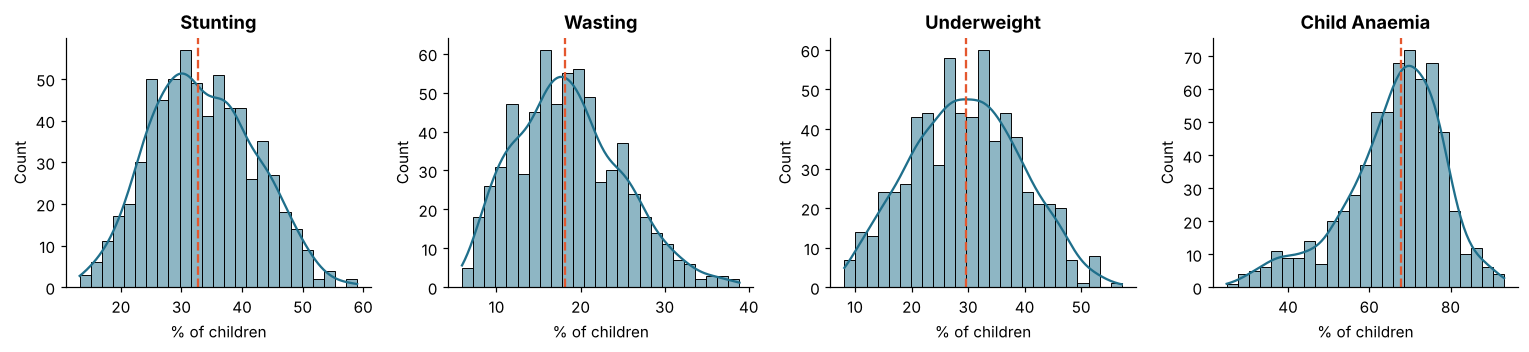

In [14]:
OUTC = ["stunting","wasting","underweight","child_anaemia"]
desc = sample[OUTC+["severe_wasting"]].describe().T[["count","mean","std","min","50%","max"]]
desc["skew"] = sample[OUTC+["severe_wasting"]].skew()
print(desc.round(1).to_string())
fig, axs = plt.subplots(1, 4, figsize=(14, 3.3))
for ax_, c in zip(axs, OUTC):
    sns.histplot(sample[c], kde=True, ax=ax_, color=C["main"], bins=25)
    ax_.axvline(sample[c].median(), color=C["accent"], ls="--", lw=1.5); ax_.set_title(c.replace("_"," ").title()); ax_.set_xlabel("% of children")
save(fig, "03_outcome_distributions")

Share of variation explained by state (eta-squared): {'stunting': '41%', 'wasting': '44%', 'underweight': '60%', 'child_anaemia': '55%', 'cmi': '59%'}


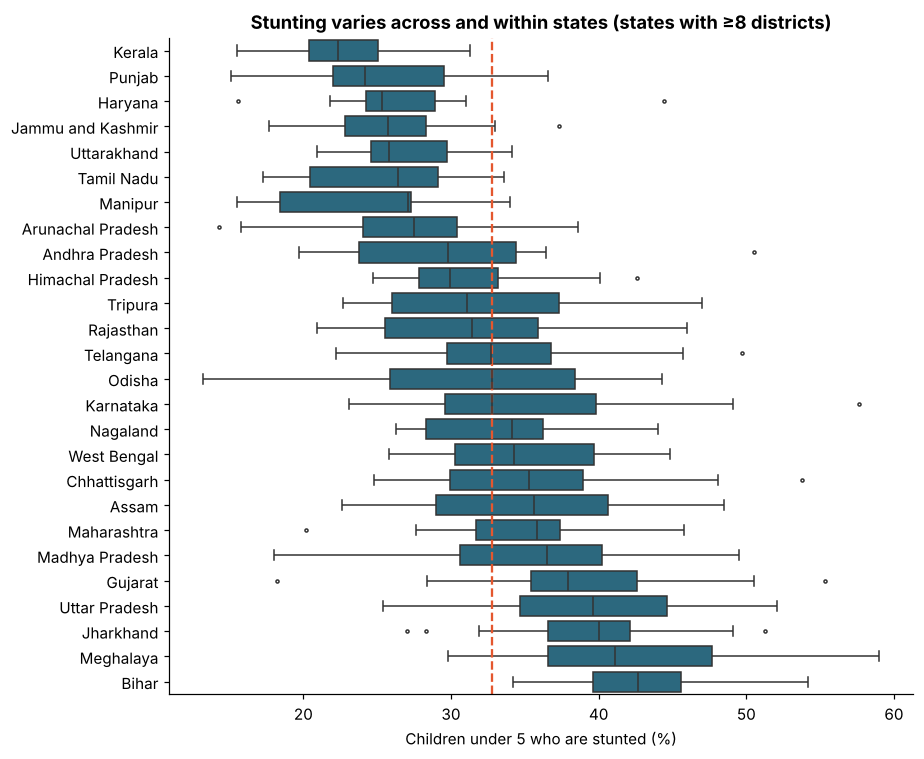

Largest within-state stunting gaps (max - min, points): {'Gujarat': 37.1, 'Karnataka': 34.5, 'Madhya Pradesh': 31.5, 'Odisha': 31.1, 'Andhra Pradesh': 30.8}


In [15]:
# regional disparity: how much of the variation lies between states vs within states?
def eta2(df, col):
    g = df.groupby("state")[col]; sst = ((df[col]-df[col].mean())**2).sum()
    ssb = (g.count()*(g.mean()-df[col].mean())**2).sum(); return ssb/sst
et = {c: eta2(sample, c) for c in OUTC+["cmi"]}
print("Share of variation explained by state (eta-squared):", {k: f"{v:.0%}" for k,v in et.items()})
st = sample.groupby("state").agg(n=("district","size"), stunting_med=("stunting","median"), stunting_min=("stunting","min"), stunting_max=("stunting","max"))
big = st[st.n>=8].sort_values("stunting_med").index
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.boxplot(data=sample[sample.state.isin(big)], y="state", x="stunting", order=big, color=C["main"], fliersize=2, ax=ax)
ax.axvline(sample.stunting.median(), color=C["accent"], ls="--"); ax.set_xlabel("Children under 5 who are stunted (%)"); ax.set_ylabel("")
ax.set_title("Stunting varies across and within states (states with ≥8 districts)")
save(fig, "04_stunting_by_state")
gap = (st.stunting_max-st.stunting_min).sort_values(ascending=False).head(5).round(1)
print("Largest within-state stunting gaps (max - min, points):", gap.to_dict())

**What we see (5.1).**
* Child malnutrition is high everywhere but very uneven: stunting runs from **13% to 59%** across districts (median 33%); two in three children are anaemic (median 68%).
* **State explains 41% of the variation in stunting and 60% of underweight.** The rest is *within* states: Gujarat's districts differ by 37 points, Karnataka's by 35. State averages hide the districts that most need help.
* Distributions are roughly symmetric (skew near 0) except child anaemia (left-skewed) and severe wasting (right-skewed), so rank-based statistics are the safe default below.

### 5.2 The agricultural side

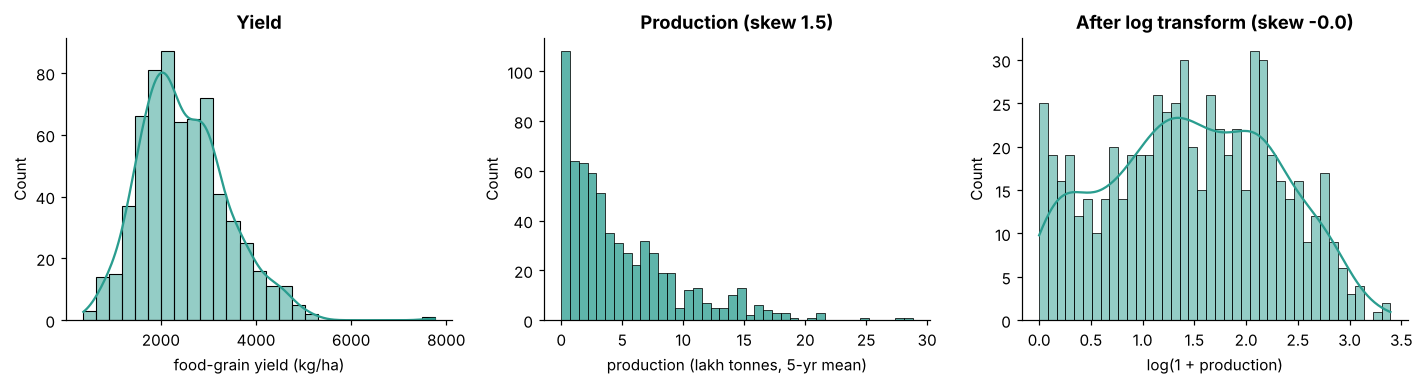

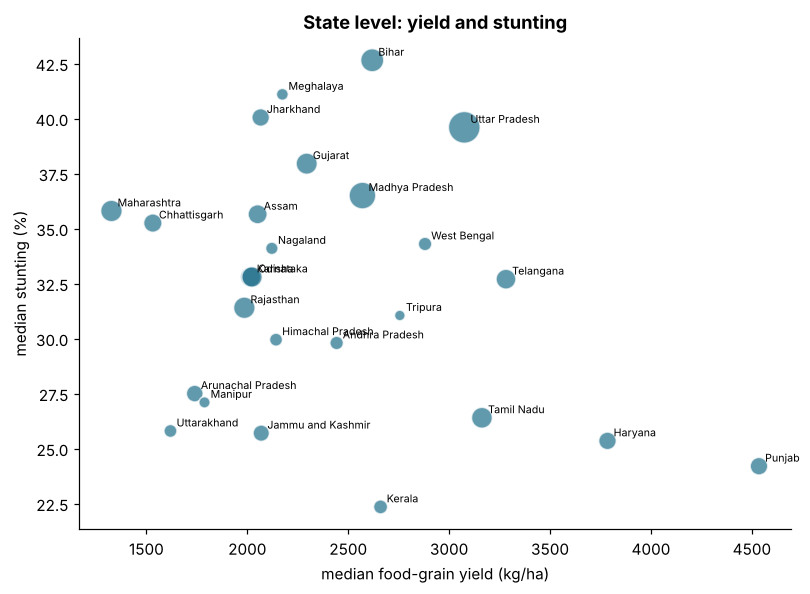

State medians (n=26): Spearman rho=-0.14, p=0.492


In [16]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
sns.histplot(sample.fg_yield, kde=True, ax=axs[0], color=C["good"]); axs[0].set_xlabel("food-grain yield (kg/ha)"); axs[0].set_title("Yield")
sns.histplot(sample.fg_prod, bins=40, ax=axs[1], color=C["good"]); axs[1].set_xlabel("production (lakh tonnes, 5-yr mean)"); axs[1].set_title(f"Production (skew {sample.fg_prod.skew():.1f})")
sns.histplot(sample.log_fg_prod, kde=True, bins=40, ax=axs[2], color=C["good"]); axs[2].set_xlabel("log(1 + production)"); axs[2].set_title(f"After log transform (skew {sample.log_fg_prod.skew():.1f})")
save(fig, "05_agri_distributions")
ys = sample.groupby("state").agg(n=("district","size"), yield_med=("fg_yield","median"), stunting_med=("stunting","median"))
ys = ys[ys.n>=8].sort_values("yield_med")
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sc = ax.scatter(ys.yield_med, ys.stunting_med, s=ys.n*6, c=C["main"], alpha=.7, edgecolor="white")
for s_, r in ys.iterrows(): ax.annotate(s_, (r.yield_med, r.stunting_med), fontsize=7, xytext=(4,3), textcoords="offset points")
ax.set_xlabel("median food-grain yield (kg/ha)"); ax.set_ylabel("median stunting (%)"); ax.set_title("State level: yield and stunting")
save(fig, "06_state_yield_vs_stunting")
rs, ps = stats.spearmanr(ys.yield_med, ys.stunting_med)
print(f"State medians (n={len(ys)}): Spearman rho={rs:.2f}, p={ps:.3f}")

### 5.3 Correlations: does production go with better nutrition?

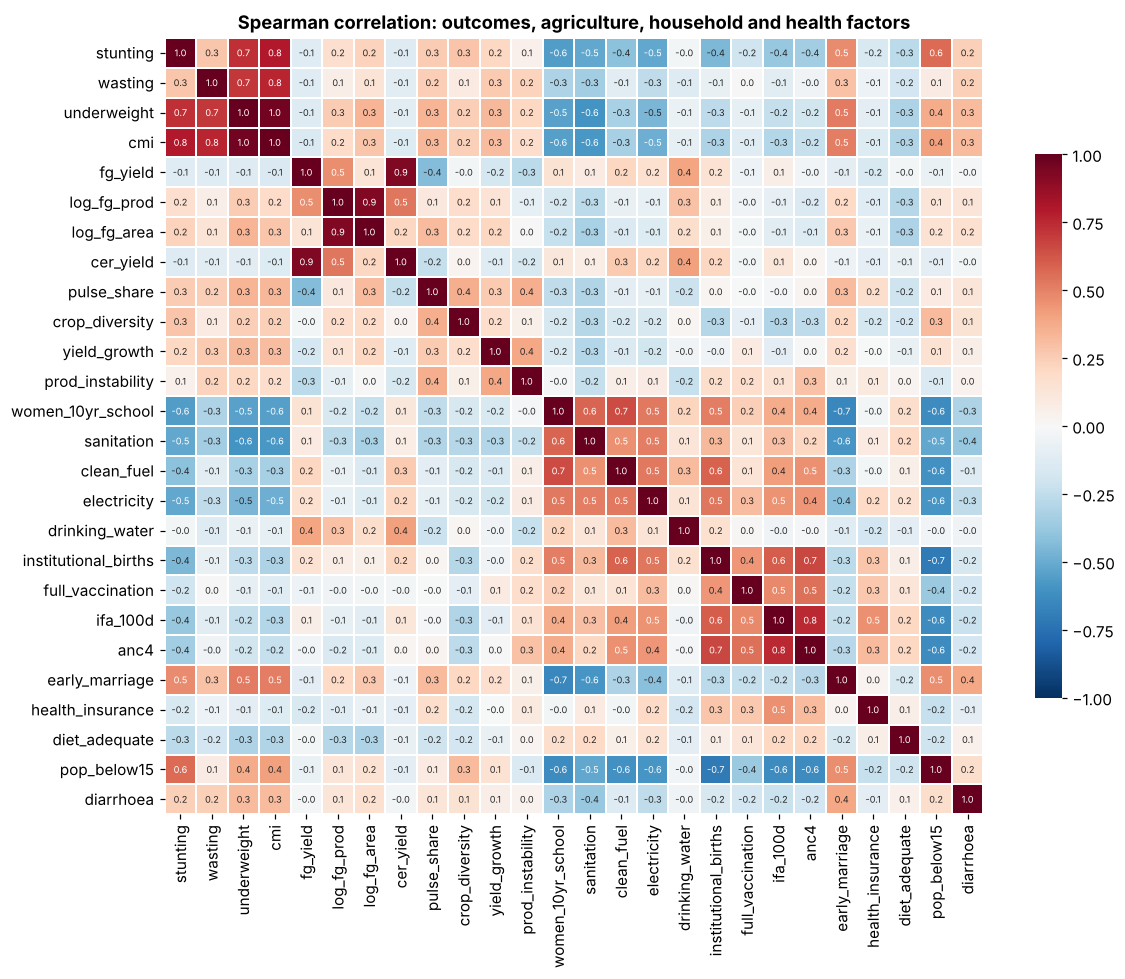

          feature   n  rho_with_stunting     p  p_adj_BH  significant
women_10yr_school 653             -0.555 0.000     0.000         True
       sanitation 653             -0.519 0.000     0.000         True
       clean_fuel 653             -0.407 0.000     0.000         True
    diet_adequate 652             -0.272 0.000     0.000         True
        cer_yield 626             -0.129 0.001     0.001         True
         fg_yield 648             -0.125 0.001     0.002         True
 prod_instability 648              0.051 0.194     0.194        False
      log_fg_prod 653              0.167 0.000     0.000         True
     yield_growth 647              0.210 0.000     0.000         True
      log_fg_area 653              0.231 0.000     0.000         True
      pulse_share 619              0.253 0.000     0.000         True
   crop_diversity 653              0.283 0.000     0.000         True


In [17]:
AGRI = ["fg_yield","log_fg_prod","log_fg_area","cer_yield","pulse_share","crop_diversity","yield_growth","prod_instability"]   # pulse yield kept in the table but not used: unreliable on small areas
DET  = ["women_10yr_school","sanitation","clean_fuel","electricity","drinking_water","institutional_births","full_vaccination","ifa_100d",
        "anc4","early_marriage","health_insurance","diet_adequate","pop_below15","diarrhoea"]
cols = OUTC[:3]+["cmi"]+AGRI+DET
corr = sample[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size":6}, linewidths=.3, ax=ax, cbar_kws={"shrink":.7})
ax.set_title("Spearman correlation: outcomes, agriculture, household and health factors")
save(fig, "07_correlation_heatmap")

rows = []
for f in AGRI + ["diet_adequate","women_10yr_school","sanitation","clean_fuel"]:
    d = sample[[f,"stunting"]].dropna(); r, p = stats.spearmanr(d[f], d.stunting); rows.append((f, len(d), r, p))
tab = pd.DataFrame(rows, columns=["feature","n","rho_with_stunting","p"]).sort_values("rho_with_stunting")
from statsmodels.stats.multitest import multipletests
tab["p_adj_BH"] = multipletests(tab.p, method="fdr_bh")[1]
tab["significant"] = tab.p_adj_BH < 0.05
print(tab.round(3).to_string(index=False))

**Reading the table.** A negative rho means "more of this goes with less stunting". Agriculture variables are compared with household and care factors side by side, so we can see which matter more.

In [18]:
# partial correlation: agriculture vs stunting after removing the effect of education, sanitation and clean fuel
ctrl = ["women_10yr_school","sanitation","clean_fuel"]
def partial_spearman(df, x, y, z):
    d = df[[x,y]+z].dropna().rank()
    Z = sm.add_constant(d[z]); rx = sm.OLS(d[x], Z).fit().resid; ry = sm.OLS(d[y], Z).fit().resid
    r, p = stats.pearsonr(rx, ry); return r, p, len(d)
prow = []
for f in ["fg_yield","log_fg_prod","pulse_share","crop_diversity","yield_growth"]:
    r0,p0 = stats.spearmanr(*sample[[f,"stunting"]].dropna().T.values)
    r1,p1,n1 = partial_spearman(sample, f, "stunting", ctrl); prow.append((f, r0, r1, p1, n1))
pt = pd.DataFrame(prow, columns=["feature","raw_rho","partial_rho","p_partial","n"])
print(pt.round(3).to_string(index=False))

       feature  raw_rho  partial_rho  p_partial   n
      fg_yield   -0.125       -0.049      0.210 648
   log_fg_prod    0.167        0.034      0.392 653
   pulse_share    0.253        0.093      0.021 619
crop_diversity    0.283        0.177      0.000 653
  yield_growth    0.210        0.078      0.046 647


            median  mean  count
yield_q                        
Q1 lowest     34.0  33.7    162
Q2            35.1  34.8    162
Q3            34.0  34.5    162
Q4 highest    30.0  31.3    162
Kruskal-Wallis H=16.6, p=0.0009


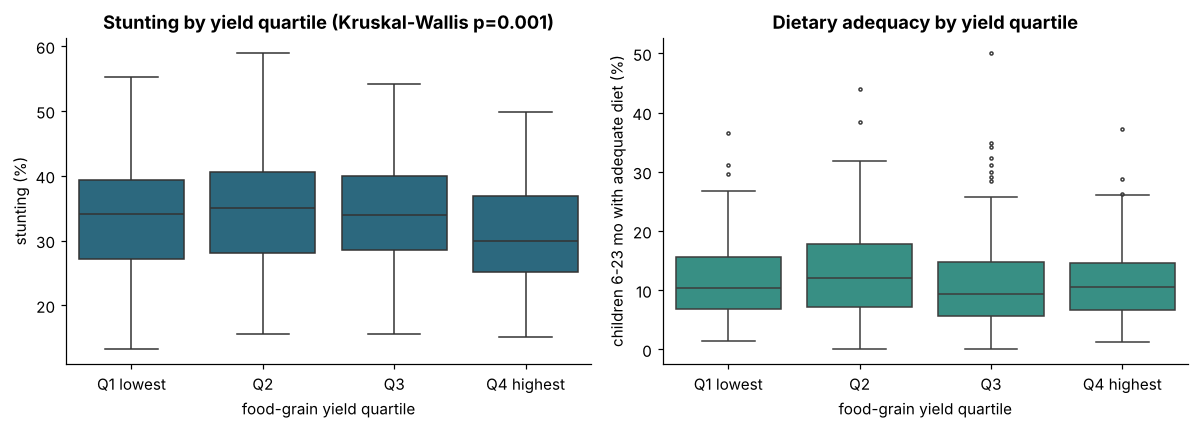

In [19]:
# yield quartiles vs stunting
sample["yield_q"] = pd.qcut(sample.fg_yield, 4, labels=["Q1 lowest","Q2","Q3","Q4 highest"])
kw = stats.kruskal(*[g.stunting.values for _, g in sample.groupby("yield_q")])
gm = sample.groupby("yield_q").stunting.agg(["median","mean","count"]).round(1); print(gm); print(f"Kruskal-Wallis H={kw.statistic:.1f}, p={kw.pvalue:.4f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=sample, x="yield_q", y="stunting", color=C["main"], ax=ax[0], fliersize=2); ax[0].set_xlabel("food-grain yield quartile"); ax[0].set_ylabel("stunting (%)")
ax[0].set_title(f"Stunting by yield quartile (Kruskal-Wallis p={kw.pvalue:.3f})")
sns.boxplot(data=sample, x="yield_q", y="diet_adequate", color=C["good"], ax=ax[1], fliersize=2); ax[1].set_xlabel("food-grain yield quartile"); ax[1].set_ylabel("children 6-23 mo with adequate diet (%)")
ax[1].set_title("Dietary adequacy by yield quartile")
save(fig, "08_yield_quartiles")

**What the correlations say (5.3).** Benjamini-Hochberg correction is applied because we test many pairs.
* **Household factors dominate.** Stunting falls with women's schooling (rho = -0.55), sanitation (-0.52), clean cooking fuel (-0.41) and adequate infant diet (-0.27).
* **Yield is only weakly linked** (rho = -0.13), and that link **disappears once education, sanitation and clean fuel are controlled** (partial rho = -0.05, p = 0.21).
* Larger farmed area, higher production and more diverse cropping go with *more* stunting. These are bigger, poorer, more populous districts, not evidence that production harms nutrition.
* The top yield quartile has lower stunting (median 30% vs about 34% in the other three quartiles, Kruskal-Wallis p = 0.001), so high productivity helps at the top end, but a district in the lower three quartiles gains nothing by being a little more productive.
* Across the 26 states with enough districts, median yield and median stunting are not related (rho = -0.14, p = 0.49).

### 5.4 Where do high output and poor nutrition coexist?
We call a district a **paradox district** when it is in the **top third of India for food-grain yield** *and* the **top third for the Child Malnutrition Index** (worse nutrition). We use yield rather than total production because total production mostly reflects district size. NFHS has no population count, so a per-person figure is not possible here (see Limitations).

In [20]:
hi_y = sample.fg_yield >= sample.fg_yield.quantile(2/3); hi_m = sample.cmi >= sample.cmi.quantile(2/3)
lo_m = sample.cmi <= sample.cmi.quantile(1/3)
sample["group"] = np.select([hi_y&hi_m, hi_y&lo_m], ["Paradox: high yield, poor nutrition","High yield, good nutrition"], "Other")
gc = sample.group.value_counts(); print(gc.to_string())
print("\nParadox districts by state:\n", sample[sample.group.str.startswith("Paradox")].state.value_counts().head(8).to_string())
print("\nTop paradox districts (highest malnutrition among high-yield districts):")
print(sample[sample.group.str.startswith("Paradox")].sort_values("cmi", ascending=False)[["state","district","fg_yield","stunting","wasting","underweight","cmi"]].head(12).round(1).to_string(index=False))

group
Other                                  506
High yield, good nutrition              88
Paradox: high yield, poor nutrition     59

Paradox districts by state:
 state
Uttar Pradesh     19
Bihar             14
Madhya Pradesh     8
Gujarat            5
Telangana          5
West Bengal        4
Rajasthan          2
Haryana            1

Top paradox districts (highest malnutrition among high-yield districts):
         state        district  fg_yield  stunting  wasting  underweight  cmi
         Bihar           Arwal    2931.8      45.6     36.8         52.9  2.2
         Bihar      Aurangabad    2832.5      41.2     32.9         48.7  1.7
         Bihar          Rohtas    3808.3      40.0     31.8         48.2  1.6
         Bihar          Araria    3542.3      49.9     23.9         47.8  1.5
         Bihar           Buxar    3089.0      39.6     33.2         45.3  1.5
         Bihar Kaimur (Bhabua)    3057.7      44.1     27.3         47.2  1.5
         Bihar         Bhojpur    3017.9 

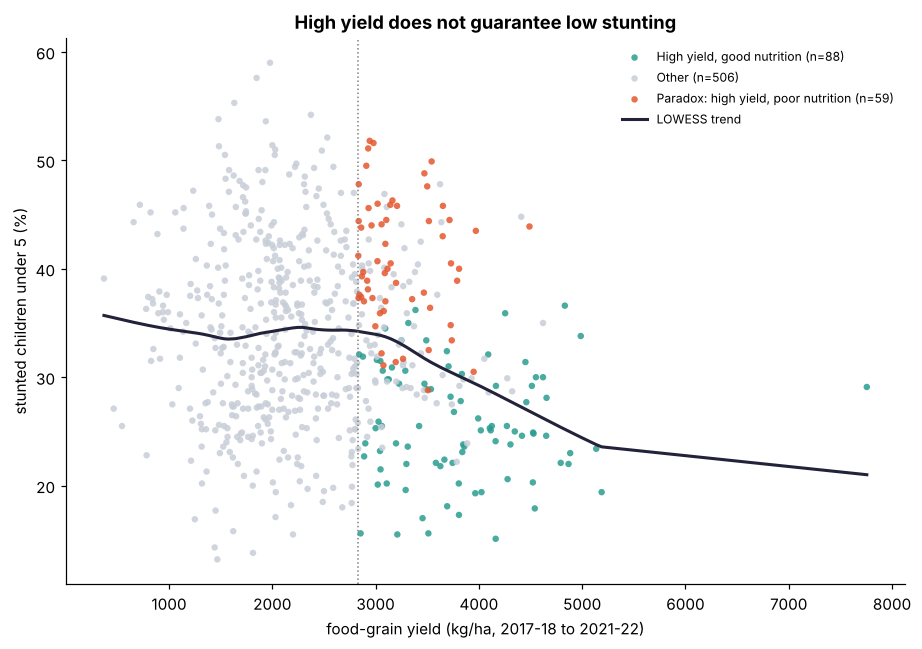

              factor  paradox_median  good_nutrition_median  difference     p  p_adj_BH
            ifa_100d          25.400                 57.850     -32.450 0.000     0.000
          clean_fuel          42.900                 75.050     -32.150 0.000     0.000
   women_10yr_school          30.000                 52.300     -22.300 0.000     0.000
          sanitation          63.300                 82.600     -19.300 0.000     0.000
institutional_births          87.600                 97.400      -9.800 0.000     0.000
    health_insurance          19.000                 28.650      -9.650 0.000     0.000
    full_vaccination          75.000                 79.050      -4.050 0.015     0.015
       diet_adequate           8.000                 11.700      -3.700 0.001     0.001
         pulse_share           0.018                  0.005       0.013 0.000     0.000
      crop_diversity           1.098                  0.764       0.334 0.000     0.000
      early_marriage          27

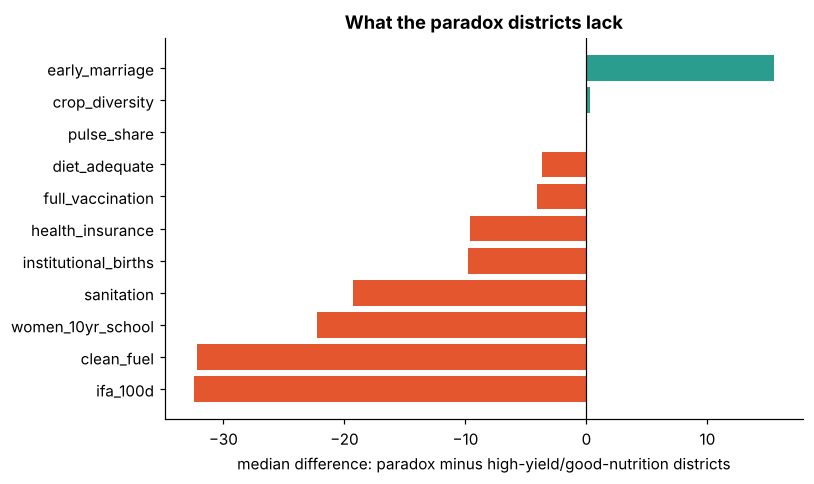

In [21]:
from statsmodels.nonparametric.smoothers_lowess import lowess
fig, ax = plt.subplots(figsize=(8.5, 6))
colors = {"Paradox: high yield, poor nutrition":C["accent"],"High yield, good nutrition":C["good"],"Other":"#c8ced8"}
for g_, d in sample.groupby("group"): ax.scatter(d.fg_yield, d.stunting, s=18, c=colors[g_], label=f"{g_} (n={len(d)})", alpha=.85, edgecolor="none")
lw = lowess(sample.stunting, sample.fg_yield, frac=.5); ax.plot(lw[:,0], lw[:,1], color=C["dark"], lw=2, label="LOWESS trend")
ax.axvline(sample.fg_yield.quantile(2/3), color="grey", ls=":", lw=1)
ax.set_xlabel("food-grain yield (kg/ha, 2017-18 to 2021-22)"); ax.set_ylabel("stunted children under 5 (%)")
ax.set_title("High yield does not guarantee low stunting"); ax.legend(fontsize=8, frameon=False)
save(fig, "09_paradox_scatter")

# what separates paradox districts from high-yield, good-nutrition districts?
P_ = sample[sample.group.str.startswith("Paradox")]; G_ = sample[sample.group=="High yield, good nutrition"]
rows = []
for f in ["diet_adequate","women_10yr_school","sanitation","clean_fuel","institutional_births","full_vaccination","ifa_100d","early_marriage","health_insurance","pulse_share","crop_diversity"]:
    a_, b_ = P_[f].dropna(), G_[f].dropna(); u_ = stats.mannwhitneyu(a_, b_)
    rows.append((f, a_.median(), b_.median(), a_.median()-b_.median(), u_.pvalue))
cmp_ = pd.DataFrame(rows, columns=["factor","paradox_median","good_nutrition_median","difference","p"]).sort_values("difference")
cmp_["p_adj_BH"] = multipletests(cmp_.p, method="fdr_bh")[1]; print(cmp_.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(7.5, 4.5)); cc = cmp_.set_index("factor").difference
ax.barh(cc.index, cc.values, color=[C["accent"] if v<0 else C["good"] for v in cc.values]); ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("median difference: paradox minus high-yield/good-nutrition districts"); ax.set_title("What the paradox districts lack")
save(fig, "10_paradox_gaps")

**What the paradox districts show (5.4).**
* **59 of 653 districts (9%)** combine top-third yield with top-third malnutrition. They cluster in **Uttar Pradesh (19), Bihar (14) and Madhya Pradesh (8)**, with the worst cases in Bihar (Arwal, Aurangabad, Rohtas, Araria, Buxar).
* Compared with the **88 high-yield districts that have good nutrition** (mostly Punjab 21, Haryana 18 and Tamil Nadu 17), paradox districts have, at the median: women with 10+ years of schooling **30% vs 52%**, clean cooking fuel **43% vs 75%**, improved sanitation **63% vs 83%**, mothers taking iron-folic acid 100+ days **25% vs 58%**, and early marriage **27% vs 11.5%**.
* **Adequate infant diet is very low in both groups** (median 8% vs 12%). High grain output is not the same as diverse, sufficient food for infants, which is why yield alone cannot close the nutrition gap.

### 5.5 Cross-source validation
If two independent sources agree on yield for the same district, we can trust the data more. We compare UPAG rice and wheat yield with the older district file.

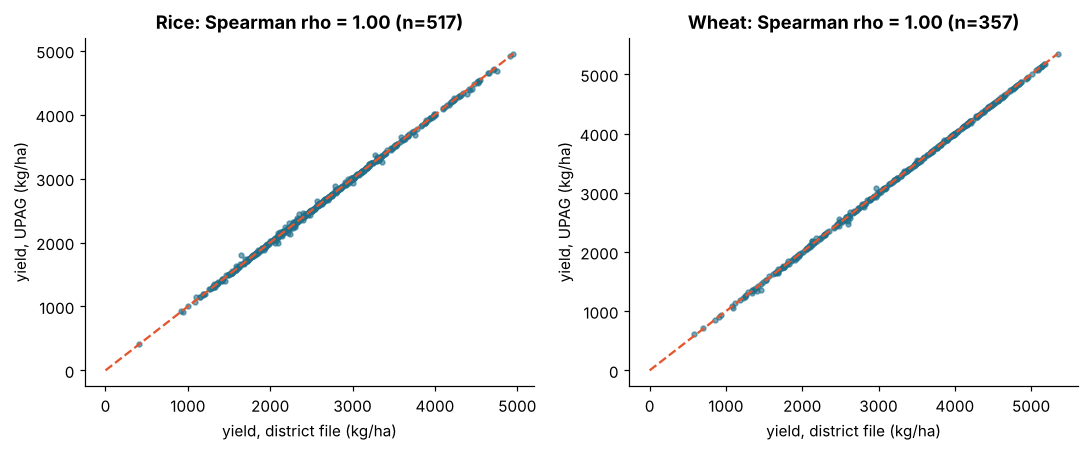

[('Rice', 517, np.float64(0.9995604461449515)), ('Wheat', 357, np.float64(0.9998173583422819))]


In [22]:
cr = crop_clean[crop_clean.Crop_Year.between(2017, 2021) & crop_clean.Crop.isin(["Rice","Wheat"])].copy()
cr["state_k"] = cr.State_Name.map(norm_state)
cr = cr.merge(m_cr[["state_k","dist_raw","nfhs_district"]].rename(columns={"dist_raw":"District_Name"}), on=["state_k","District_Name"])
cry = cr.dropna(subset=["Production","Area"]).groupby(["state_k","nfhs_district","Crop"]).apply(lambda g: g.Production.sum()/g.Area.sum()*1000).rename("yield_old").reset_index()
chk = []
fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
for ax_, (cname, ucol) in zip(axs, [("Rice","rice_yield"),("Wheat","wheat_yield")]):
    d = cry[cry.Crop==cname].merge(master[["state_k","district",ucol]], left_on=["state_k","nfhs_district"], right_on=["state_k","district"]).dropna(subset=[ucol,"yield_old"])
    d = d[(d.yield_old>0)&(d[ucol]>0)]; r, p = stats.spearmanr(d.yield_old, d[ucol]); chk.append((cname, len(d), r))
    ax_.scatter(d.yield_old, d[ucol], s=10, c=C["main"], alpha=.6); mx = max(d.yield_old.max(), d[ucol].max()); ax_.plot([0,mx],[0,mx], color=C["accent"], ls="--")
    ax_.set_xlabel("yield, district file (kg/ha)"); ax_.set_ylabel("yield, UPAG (kg/ha)"); ax_.set_title(f"{cname}: Spearman rho = {r:.2f} (n={len(d)})")
save(fig, "11_cross_source_validation"); print(chk)

**Validation result.** The two district files agree almost perfectly (Spearman rho about 0.9996 for rice and 0.9998 for wheat). Note both ultimately come from state agriculture departments, so this is **not independent confirmation of the numbers**. It confirms that our district matching and cleaning did not scramble or distort the data.

### 5.6 Maps: where is the gap?
Boundaries are the 2011-era district map. Districts created later have no polygon (shown grey), so the map covers about four in five NFHS districts.

polygons with nutrition data: 561 of 594 | with agriculture data: 543


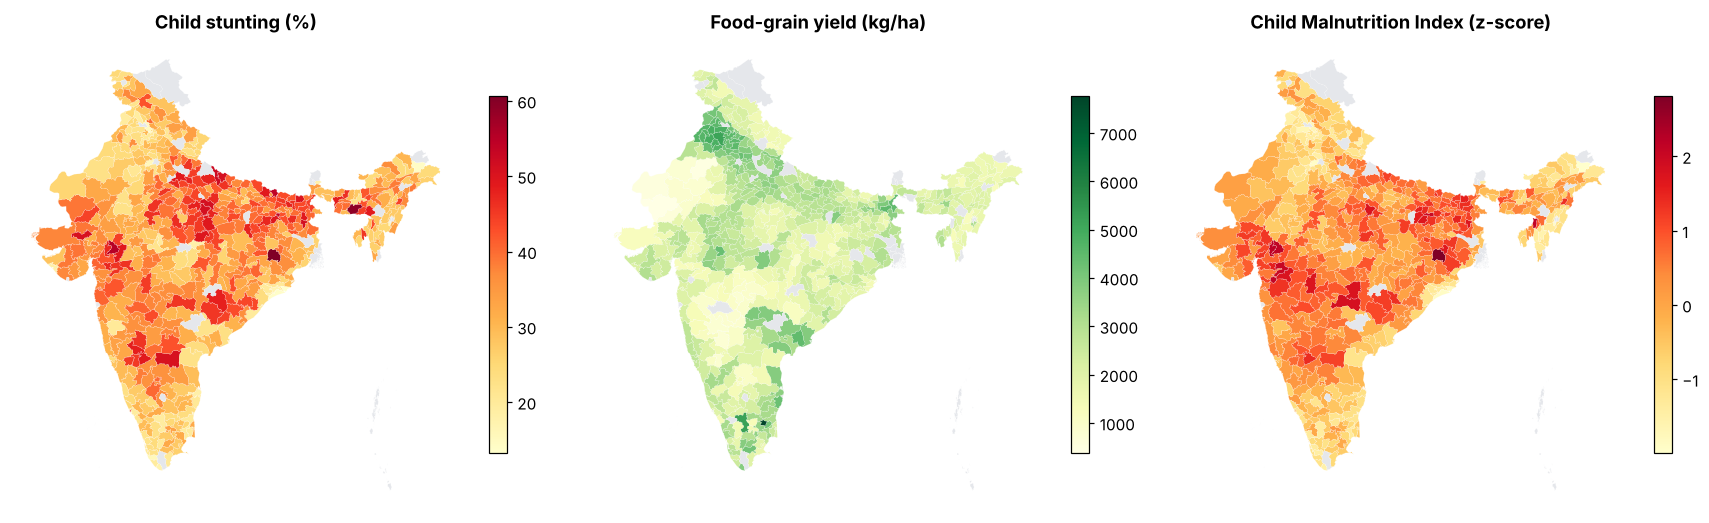

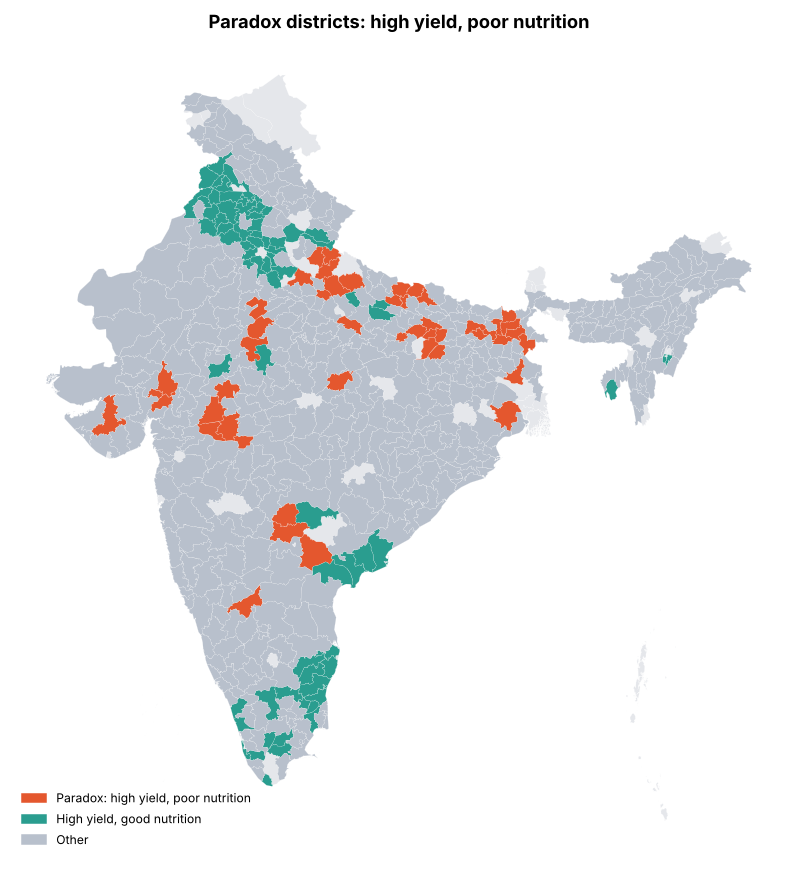

In [23]:
import geopandas as gpd
gj = gpd.read_file(RAW/"india_districts_simplified.geojson")
mp = gj.merge(master[["state_k","district","stunting","fg_yield","cmi"]].merge(sample[["state_k","district","group"]], on=["state_k","district"], how="left"),
              left_on=["state_k","nfhs_district"], right_on=["state_k","district"], how="left")
print("polygons with nutrition data:", mp.stunting.notna().sum(), "of", len(mp), "| with agriculture data:", mp.fg_yield.notna().sum())
fig, axs = plt.subplots(1, 3, figsize=(16, 6.2))
for ax_, col, cmap, ttl in zip(axs, ["stunting","fg_yield","cmi"], ["YlOrRd","YlGn","YlOrRd"],
        ["Child stunting (%)","Food-grain yield (kg/ha)","Child Malnutrition Index (z-score)"]):
    mp.plot(column=col, cmap=cmap, legend=True, ax=ax_, linewidth=.1, edgecolor="white", missing_kwds={"color":"#e5e7eb"}, legend_kwds={"shrink":.55})
    ax_.set_axis_off(); ax_.set_title(ttl)
save(fig, "12_maps")
fig, ax = plt.subplots(figsize=(7.5, 8))
mp.plot(color="#e5e7eb", ax=ax, linewidth=.1, edgecolor="white")
cmap_ = {"Paradox: high yield, poor nutrition":C["accent"],"High yield, good nutrition":C["good"],"Other":"#b8c0cc"}
for g_, col in cmap_.items(): mp[mp.group==g_].plot(color=col, ax=ax, linewidth=.1, edgecolor="white")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=l) for l, c in cmap_.items()], loc="lower left", frameon=False, fontsize=8); ax.set_axis_off()
ax.set_title("Paradox districts: high yield, poor nutrition")
save(fig, "13_paradox_map")

### 5.7 State context: staple price volatility and FCI procurement
These are **state-level** figures, so they enter only a state-level comparison (few states). They are not mixed into district analysis.

   state_feature  n_states  rho_with_mean_stunting     p
price_vol_basket        17                  -0.385 0.127
fci_procured_lmt        24                   0.195 0.362


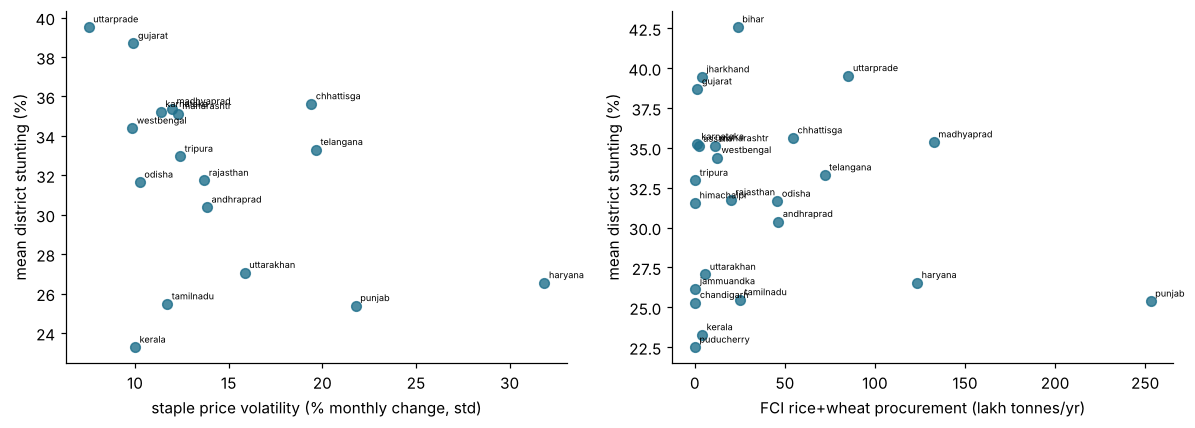

In [24]:
sg = sample.groupby("state_k").agg(stunting=("stunting","mean"), fg_yield=("fg_yield","median"), n=("district","size")).reset_index().merge(state_ctx, on="state_k")
rows = []
for f in ["price_vol_basket","fci_procured_lmt"]:
    d = sg[["stunting",f]].dropna(); r, p = stats.spearmanr(d.stunting, d[f]); rows.append((f, len(d), r, p))
print(pd.DataFrame(rows, columns=["state_feature","n_states","rho_with_mean_stunting","p"]).round(3).to_string(index=False))
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax_, f, lab in zip(axs, ["price_vol_basket","fci_procured_lmt"], ["staple price volatility (% monthly change, std)","FCI rice+wheat procurement (lakh tonnes/yr)"]):
    d = sg.dropna(subset=[f]); ax_.scatter(d[f], d.stunting, s=40, c=C["main"], alpha=.8)
    for _, r in d.iterrows(): ax_.annotate(r.state_k[:10], (r[f], r.stunting), fontsize=6, xytext=(3,3), textcoords="offset points")
    ax_.set_xlabel(lab); ax_.set_ylabel("mean district stunting (%)")
save(fig, "14_state_context")

## 6. Preprocessing for modelling

Candidate predictors: agriculture and household/health factors. The target is stunting.

**Validation safeguard:** clipping limits, skew transformations, scaling, KNN imputation, and correlation filtering are learned separately inside each cross-validation training fold (Cell 50). This prevents validation-fold information from leaking into model fitting.

Cell 47 also creates a full-sample, exploratory `X4` matrix for descriptive plots and downstream explanatory analyses. Do not use that full-sample matrix to report cross-validation performance.

The original raw and cleaned source tables are preserved; preprocessing for modelling does not overwrite them.

In [25]:
# Leakage-safe preprocessing components.
# These transformers are fitted inside each CV training fold in Cell 50.
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import KNNImputer
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score
from sklearn.linear_model import Lasso
from sklearn.feature_selection import SelectKBest, f_regression

class WinsorSkewTransformer(BaseEstimator, TransformerMixin):
    """Learn clipping bounds and skew transforms from training data only."""
    def __init__(self, lower=0.01, upper=0.99, skew_threshold=1.0):
        self.lower, self.upper, self.skew_threshold = lower, upper, skew_threshold

    def fit(self, X, y=None):
        X = pd.DataFrame(X).copy()
        self.columns_ = list(X.columns)
        self.lower_ = X.quantile(self.lower)
        self.upper_ = X.quantile(self.upper)
        Xw = X.clip(self.lower_, self.upper_, axis=1)
        sk = Xw.skew()
        self.log_cols_ = [c for c in self.columns_ if sk[c] > self.skew_threshold and Xw[c].min(skipna=True) >= 0]
        self.ref_cols_ = [c for c in self.columns_ if sk[c] < -self.skew_threshold]
        self.maxima_ = Xw.max()
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.columns_).copy()
        X = X.clip(self.lower_, self.upper_, axis=1)
        for c in self.log_cols_:
            X[c] = np.log1p(X[c])
        for c in self.ref_cols_:
            X[c] = -np.log1p((self.maxima_[c] - X[c]).clip(lower=0))
        return X

class ScaleForKNN(BaseEstimator, TransformerMixin):
    """Estimate scaling on median-filled training data, but preserve NaNs for KNN."""
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        med = np.nanmedian(X, axis=0)
        med = np.where(np.isfinite(med), med, 0.0)
        filled = np.where(np.isnan(X), med, X)
        self.mean_ = filled.mean(axis=0)
        self.scale_ = filled.std(axis=0)
        self.scale_[self.scale_ == 0] = 1.0
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return (X - self.mean_) / self.scale_

class CorrelationFilter(BaseEstimator, TransformerMixin):
    """Remove one of each highly correlated pair using training-fold data only."""
    def __init__(self, threshold=0.85):
        self.threshold = threshold

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        corr = np.corrcoef(X, rowvar=False)
        if np.ndim(corr) == 0:
            corr = np.array([[1.0]])
        target = np.array([
            abs(np.corrcoef(X[:, j], y)[0, 1])
            if np.std(X[:, j]) > 0 and np.std(y) > 0 else 0.0
            for j in range(X.shape[1])
        ])
        target = np.nan_to_num(target, nan=0.0, posinf=0.0, neginf=0.0)
        drop = set()
        for i in range(X.shape[1]):
            for j in range(i + 1, X.shape[1]):
                if i in drop or j in drop:
                    continue
                pair_corr = corr[i, j]
                if np.isfinite(pair_corr) and abs(pair_corr) > self.threshold:
                    drop.add(i if target[i] < target[j] else j)
        self.keep_indices_ = [i for i in range(X.shape[1]) if i not in drop]
        if not self.keep_indices_:
            self.keep_indices_ = [0]
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.keep_indices_]

FEATS = AGRI + DET
X0 = sample[FEATS].copy()
y = sample.stunting.loc[X0.index]
groups = sample.state.loc[X0.index]

# Full-sample matrix retained ONLY for descriptive plots/tables and downstream
# descriptive analyses. Do not use this matrix to report CV performance.
exploratory_preprocess = Pipeline([
    ("winsor_skew", WinsorSkewTransformer()),
    ("scale_for_knn", ScaleForKNN()),
    ("knn", KNNImputer(n_neighbors=5))
])
X4 = pd.DataFrame(exploratory_preprocess.fit_transform(X0), columns=FEATS, index=X0.index)
rep = pd.DataFrame({
    "missing_before": X0.isna().sum(),
    "skew_before": X0.skew().round(2),
    "transform": ["log" if c in exploratory_preprocess.named_steps["winsor_skew"].log_cols_
                  else ("reflected log" if c in exploratory_preprocess.named_steps["winsor_skew"].ref_cols_ else "")
                  for c in FEATS],
    "missing_after": X4.isna().sum()
})
print(rep.to_string())
print("Exploratory full-sample preprocessing complete. CV evaluation uses fold-fitted pipelines in Cell 50.")


                      missing_before  skew_before      transform  missing_after
fg_yield                           5         0.69                             0
log_fg_prod                        0        -0.02                             0
log_fg_area                        0         0.22                             0
cer_yield                         27         0.53                             0
pulse_share                       34         3.00            log              0
crop_diversity                     0        -0.65                             0
yield_growth                       6         1.28                             0
prod_instability                   5         1.98            log              0
women_10yr_school                  0         0.55                             0
sanitation                         0        -0.45                             0
clean_fuel                         0         0.21                             0
electricity                        0    

In [26]:
# Descriptive full-sample multicollinearity diagnostic.
# This KEEP list supports descriptive follow-on analyses only. The fair CV
# evaluation applies CorrelationFilter inside each training fold in Cell 50.
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
v = pd.Series([vif(X4.values, i) for i in range(X4.shape[1])], index=FEATS).sort_values(ascending=False)
print("Highest VIF (exploratory full-sample diagnostic):\n", v.head(6).round(1).to_string())
cm_ = X4.corr().abs(); tgt = X4.corrwith(y).abs(); drop = set()
for i, a_ in enumerate(FEATS):
    for b_ in FEATS[i+1:]:
        if a_ in drop or b_ in drop: continue
        if cm_.loc[a_, b_] > 0.85: drop.add(a_ if tgt[a_] < tgt[b_] else b_)
KEEP = [f for f in FEATS if f not in drop]
print("Exploratory dropped features for |r| > 0.85:", sorted(drop), "| kept:", len(KEEP))
log("Preprocessing","exploratory collinear features (|r|>0.85)", str(sorted(drop)), "dropped weaker correlate; CV uses fold-specific filtering")


Highest VIF (exploratory full-sample diagnostic):
 log_fg_prod    57.1
log_fg_area    43.5
fg_yield       18.5
cer_yield      13.5
anc4            3.7
pop_below15     3.5
Exploratory dropped features for |r| > 0.85: ['cer_yield', 'log_fg_prod'] | kept: 20


### 6.1 Feature selection and a fair test of "does agriculture explain nutrition?"
We compare three feature sets with a random forest:
* **Agriculture only**
* **Household and health factors only**
* **Both**

We report two scores. **Random 5-fold** lets neighbouring districts of the same state sit on both sides (optimistic). **Leave-states-out** (`GroupKFold`) tests districts in states the model has never seen, which is the honest test.

            feature set  n_features  R2 random 5-fold  R2 leave-states-out
       Agriculture only           8             0.235               -0.039
Household & health only          14             0.493                0.288
                   Both          22             0.506                0.290


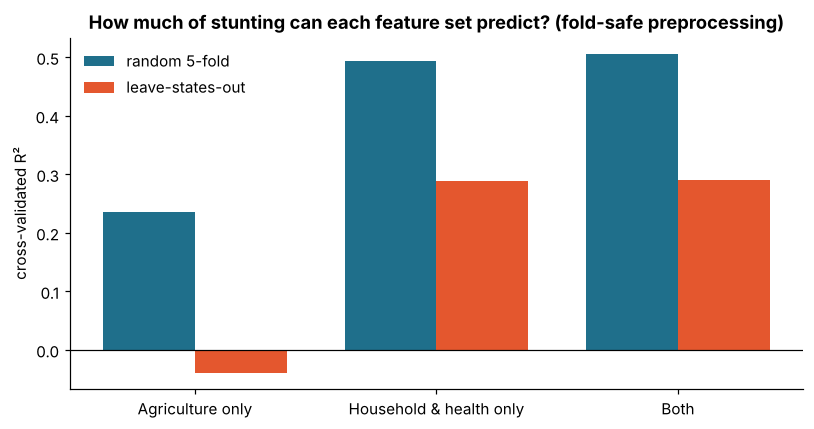

In [27]:
# Fair evaluation: every learned preprocessing step is fitted only on each
# training fold. This prevents validation-fold information leaking into training.
from sklearn.model_selection import GroupKFold

def make_model_pipeline():
    return Pipeline([
        ("winsor_skew", WinsorSkewTransformer()),
        ("scale_for_knn", ScaleForKNN()),
        ("knn", KNNImputer(n_neighbors=5, keep_empty_features=True)),
        ("corr_filter", CorrelationFilter(threshold=0.85)),
        ("model", RandomForestRegressor(
            n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1
        ))
    ])

sets = {
    "Agriculture only": [f for f in AGRI if f in X0.columns],
    "Household & health only": [f for f in DET if f in X0.columns],
    "Both": FEATS
}
random_cv = KFold(5, shuffle=True, random_state=42)
n_groups = groups.nunique()
group_cv = GroupKFold(n_splits=min(5, n_groups))
res = []
for nm, fs in sets.items():
    model = make_model_pipeline()
    r1 = cross_val_score(model, X0[fs], y, cv=random_cv, scoring="r2", n_jobs=1).mean()
    r2 = cross_val_score(model, X0[fs], y, cv=group_cv, groups=groups, scoring="r2", n_jobs=1).mean()
    res.append((nm, len(fs), r1, r2))
cvres = pd.DataFrame(res, columns=["feature set","n_features","R2 random 5-fold","R2 leave-states-out"])
print(cvres.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(7.5, 4)); x_ = np.arange(len(cvres)); w_ = .38
ax.bar(x_-w_/2, cvres["R2 random 5-fold"], w_, color=C["main"], label="random 5-fold")
ax.bar(x_+w_/2, cvres["R2 leave-states-out"], w_, color=C["accent"], label="leave-states-out")
ax.set_xticks(x_); ax.set_xticklabels(cvres["feature set"]); ax.axhline(0, color="k", lw=.8)
ax.set_ylabel("cross-validated R²"); ax.legend(frameon=False)
ax.set_title("How much of stunting can each feature set predict? (fold-safe preprocessing)")
save(fig, "15_model_comparison")


Exploratory Lasso kept 11 of 20 features (alpha=0.430)


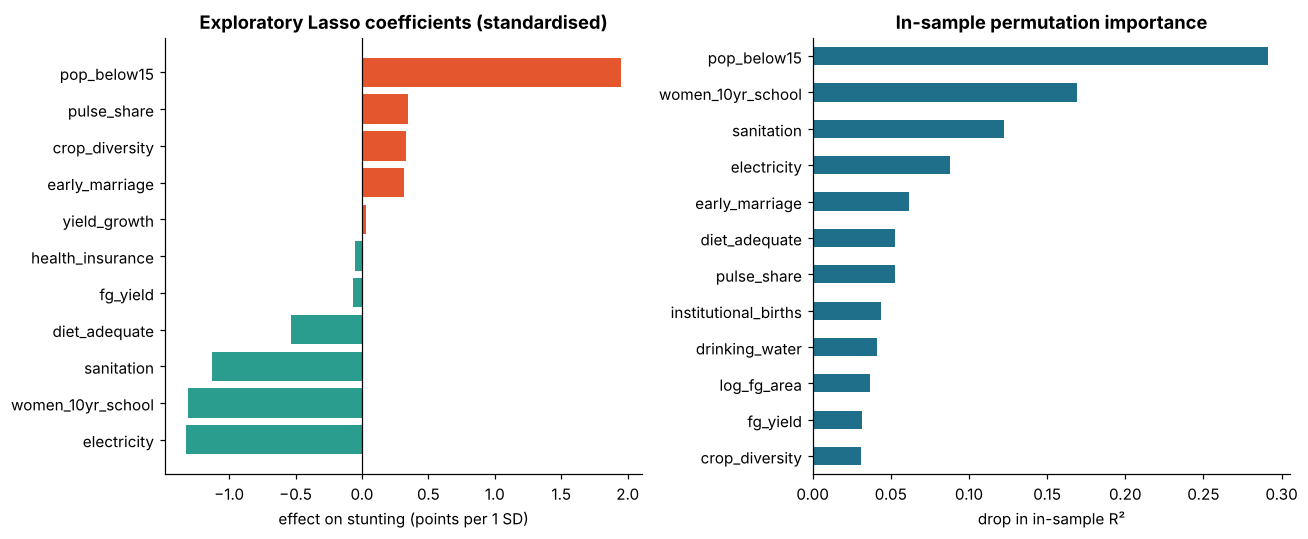

Exploratory top 8 by permutation importance: ['pop_below15', 'women_10yr_school', 'sanitation', 'electricity', 'early_marriage', 'diet_adequate', 'pulse_share', 'institutional_births']


In [28]:
# Exploratory feature interpretation on the full sample.
# These rankings are descriptive, not an unbiased estimate of out-of-sample
# feature importance. For predictive claims, compute importance on held-out folds.
lasso = LassoCV(cv=5, random_state=42).fit(X4[KEEP], y)
coef = pd.Series(lasso.coef_, index=KEEP); sel = coef[coef.abs()>1e-6].sort_values()
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1).fit(X4[KEEP], y)
pi = permutation_importance(rf, X4[KEEP], y, n_repeats=15, random_state=42, n_jobs=-1)
imp_ = pd.Series(pi.importances_mean, index=KEEP).sort_values()
print(f"Exploratory Lasso kept {len(sel)} of {len(KEEP)} features (alpha={lasso.alpha_:.3f})")
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].barh(sel.index, sel.values, color=[C["good"] if v<0 else C["accent"] for v in sel.values]); ax[0].axvline(0, color="k", lw=.8)
ax[0].set_title("Exploratory Lasso coefficients (standardised)"); ax[0].set_xlabel("effect on stunting (points per 1 SD)")
imp_.tail(12).plot.barh(ax=ax[1], color=C["main"]); ax[1].set_title("In-sample permutation importance"); ax[1].set_xlabel("drop in in-sample R²")
save(fig, "16_feature_selection")
SELECTED = list(imp_.sort_values(ascending=False).head(8).index)
print("Exploratory top 8 by permutation importance:", SELECTED)


In [29]:
# interpretable regression with robust errors and state fixed effects
Xols = sm.add_constant(pd.concat([X4[["fg_yield","women_10yr_school","sanitation","clean_fuel","diet_adequate","ifa_100d"]],
                                  pd.get_dummies(groups, drop_first=True, dtype=float)], axis=1))
ols = sm.OLS(y, Xols).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(groups)[0]})
tbl = pd.DataFrame({"coef":ols.params, "se":ols.bse, "p":ols.pvalues}).loc[["fg_yield","women_10yr_school","sanitation","clean_fuel","diet_adequate","ifa_100d"]]
print(tbl.round(3).to_string()); print(f"R² = {ols.rsquared:.2f} | adj R² = {ols.rsquared_adj:.2f} | n = {int(ols.nobs)} | standard errors clustered by state, state fixed effects included")

                    coef     se      p
fg_yield          -1.051  0.375  0.005
women_10yr_school -3.206  0.564  0.000
sanitation        -2.156  0.432  0.000
clean_fuel        -0.740  0.610  0.225
diet_adequate     -0.080  0.298  0.789
ifa_100d          -0.271  0.646  0.675
R² = 0.58 | adj R² = 0.56 | n = 653 | standard errors clustered by state, state fixed effects included


**Interpreting the modelling results (cells 50-52).**
* **Leave-states-out is the honest test** (whole states are held out, so the model must work in states it has never seen). Agriculture alone scores R² = -0.04: no better than predicting the average. Household and health factors score 0.29, and adding agriculture to them changes almost nothing (0.29).
* Random 5-fold scores are higher (0.24 / 0.49 / 0.51) because districts of the same state sit in both training and test folds, so they partly measure state identity. We report them only as the optimistic comparison.
* Even with state fixed effects and state-clustered errors, food-grain yield keeps a small negative coefficient on stunting (-1.05 points per standard deviation, p = 0.005), while women's schooling (-3.2) and sanitation (-2.2) are three times larger. The model explains R² = 0.58 of stunting.
* Feature selection is exploratory (full sample): Lasso kept 11 of 20 features; permutation importance is led by population share under 15, women's schooling and sanitation.
* All results are observational associations, not causal effects. NFHS and agriculture data cover different periods and district boundaries.

## 7. Principal Component Analysis
### 7.1 PCA on the nutrition outcomes
Seven nutrition outcomes move together. PCA shows whether one number can summarise them.

explained variance: [52.3 19.1 14.3]
                 PC1   PC2
stunting        0.35 -0.28
wasting         0.40  0.50
underweight     0.48  0.03
severe_wasting  0.31  0.63
child_anaemia   0.34 -0.31
women_low_bmi   0.41 -0.24
women_anaemia   0.32 -0.34
corr(PC1, CMI) = 0.931


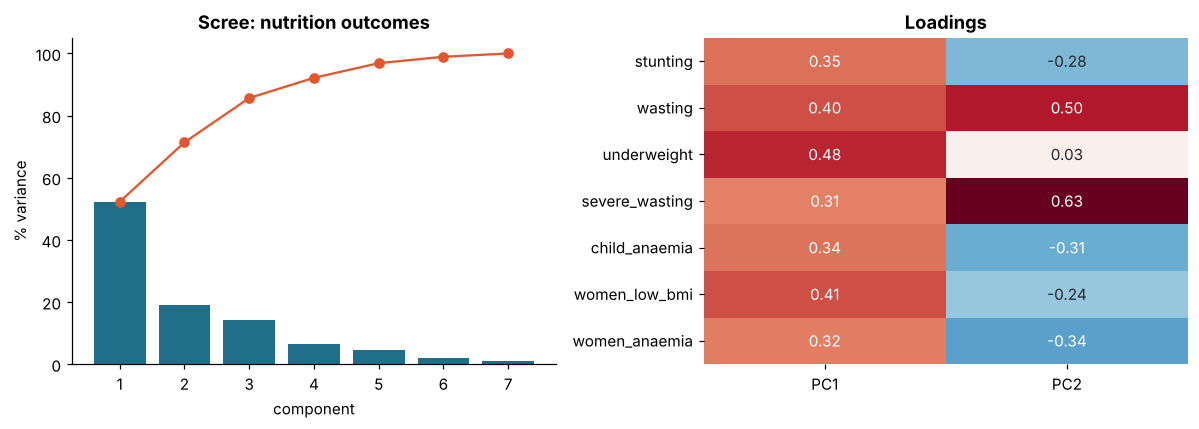

In [30]:
OUT7 = ["stunting","wasting","underweight","severe_wasting","child_anaemia","women_low_bmi","women_anaemia"]
O = sample[OUT7].dropna(); Os = StandardScaler().fit_transform(O)
pa = PCA().fit(Os); ev = pa.explained_variance_ratio_
load = pd.DataFrame(pa.components_[:2].T, index=OUT7, columns=["PC1","PC2"])
print("explained variance:", (ev[:3]*100).round(1)); print(load.round(2).to_string())
pc1 = pd.Series(Os @ pa.components_[0], index=O.index)
if load.loc["stunting","PC1"] < 0: pc1 = -pc1                      # orient so higher = worse
print("corr(PC1, CMI) =", round(np.corrcoef(pc1, sample.loc[O.index,"cmi"])[0,1], 3))
sample["pca_burden"] = pc1
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(range(1, len(ev)+1), ev*100, color=C["main"]); ax[0].plot(range(1, len(ev)+1), np.cumsum(ev)*100, "o-", color=C["accent"]); ax[0].set_xlabel("component"); ax[0].set_ylabel("% variance"); ax[0].set_title("Scree: nutrition outcomes")
sns.heatmap(load, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[1], cbar=False); ax[1].set_title("Loadings")
save(fig, "17_pca_outcomes")

### 7.2 PCA on the predictors (agriculture + household/health)
Here PCA reduces correlated predictors to a few independent components.

components for 80% variance: 10 of 20 | for 90%: 13
PC1 corr with stunting: 0.64
PC2 corr with stunting: 0.14
PC3 corr with stunting: 0.11


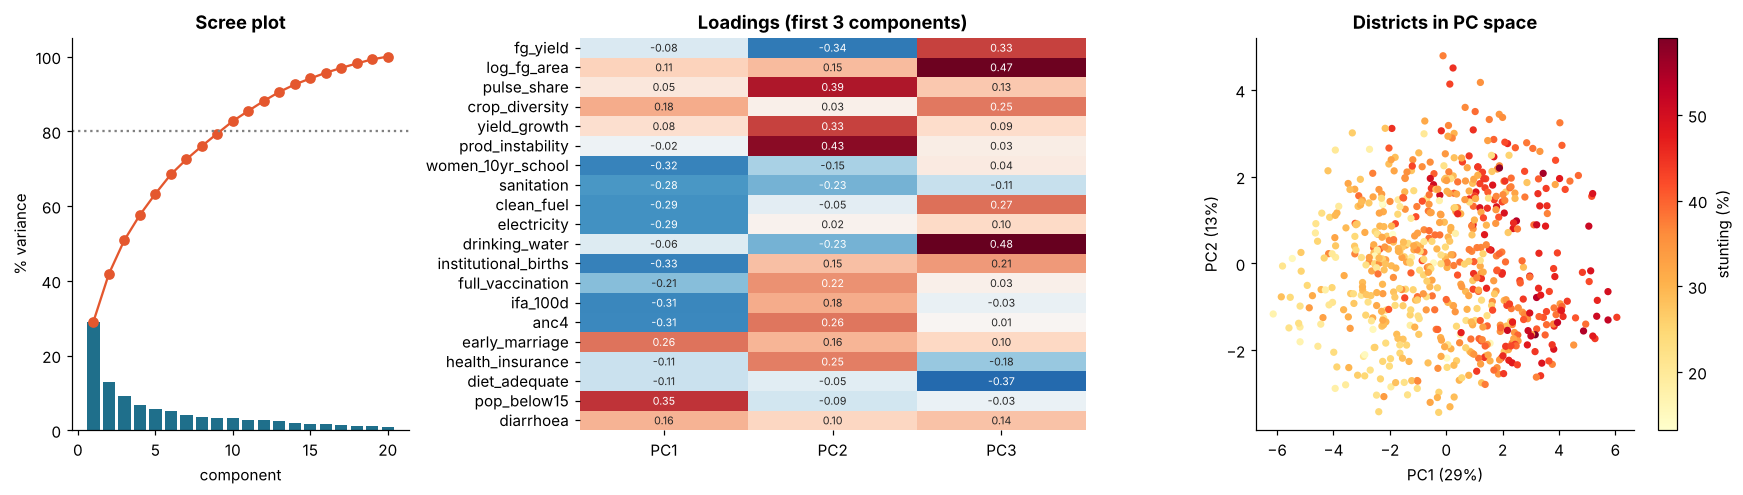

In [31]:
pp = PCA().fit(X4[KEEP]); evp = pp.explained_variance_ratio_; cum = np.cumsum(evp)
k80 = int(np.argmax(cum>=.80))+1; k90 = int(np.argmax(cum>=.90))+1
print(f"components for 80% variance: {k80} of {len(KEEP)} | for 90%: {k90}")
L = pd.DataFrame(pp.components_[:3].T, index=KEEP, columns=["PC1","PC2","PC3"])
scores = pd.DataFrame(pp.transform(X4[KEEP])[:,:3], index=X4.index, columns=["PC1","PC2","PC3"])
for c in ["PC1","PC2","PC3"]: print(c, "corr with stunting:", round(stats.spearmanr(scores[c], y)[0],2))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios":[1,1.5,1.4]})
ax[0].bar(range(1, len(evp)+1), evp*100, color=C["main"]); ax[0].plot(range(1, len(evp)+1), cum*100, "o-", color=C["accent"]); ax[0].axhline(80, color="grey", ls=":"); ax[0].set_xlabel("component"); ax[0].set_ylabel("% variance"); ax[0].set_title("Scree plot")
sns.heatmap(L, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[1], cbar=False, annot_kws={"size":7}); ax[1].set_title("Loadings (first 3 components)")
sc_ = ax[2].scatter(scores.PC1, scores.PC2, c=sample.loc[X4.index,"stunting"], cmap="YlOrRd", s=14); plt.colorbar(sc_, ax=ax[2], label="stunting (%)")
ax[2].set_xlabel(f"PC1 ({evp[0]*100:.0f}%)"); ax[2].set_ylabel(f"PC2 ({evp[1]*100:.0f}%)"); ax[2].set_title("Districts in PC space")
save(fig, "18_pca_predictors")

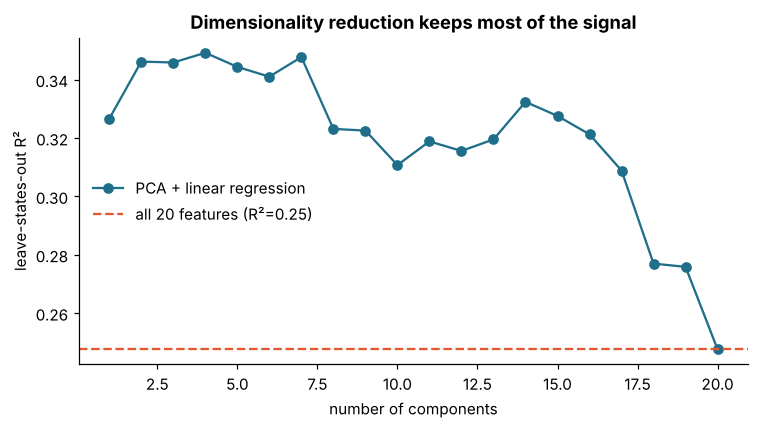

best k=4, R2=0.35 | all features R2=0.25


In [32]:
# does PCA preserve predictive power? principal-component regression
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
ks = list(range(1, len(KEEP)+1)); r2k = []
for k in ks:
    pipe = make_pipeline(PCA(n_components=k), LinearRegression())
    r2k.append(cross_val_score(pipe, X4[KEEP], y, cv=GroupKFold(5), groups=groups, scoring="r2").mean())
full = cross_val_score(LinearRegression(), X4[KEEP], y, cv=GroupKFold(5), groups=groups, scoring="r2").mean()
fig, ax = plt.subplots(figsize=(7, 4)); ax.plot(ks, r2k, "o-", color=C["main"], label="PCA + linear regression"); ax.axhline(full, color=C["accent"], ls="--", label=f"all {len(KEEP)} features (R²={full:.2f})")
ax.set_xlabel("number of components"); ax.set_ylabel("leave-states-out R²"); ax.legend(frameon=False); ax.set_title("Dimensionality reduction keeps most of the signal"); save(fig, "19_pcr")
best_k = ks[int(np.argmax(r2k))]; print(f"best k={best_k}, R2={max(r2k):.2f} | all features R2={full:.2f}")

**What PCA shows (7).**
* **Outcomes:** the first component holds **52%** of the variance, with all seven indicators loading the same way, so a single malnutrition burden axis exists (correlation with our z-score index 0.93). The second component (19%) separates **acute** problems (wasting, severe wasting) from **chronic** ones (stunting, anaemia), showing the two are not the same districts.
* **Predictors:** PC1 (29%) is a **household development axis** (schooling, sanitation, clean fuel, electricity, institutional births and antenatal care on one side; early marriage and young population on the other). PC2 (13%) is an **agricultural variability axis** (pulse share, production instability, yield growth). It takes 10 of 20 components to reach 80% of the variance, so the predictors are only moderately redundant.
* PC1 correlates with stunting at rho = 0.64, far more than any agricultural feature. Principal-component regression with 4 components scores R² = 0.35 on unseen states, versus 0.25 with all 20 features in a plain linear model, so reducing dimensions helps by removing collinearity.

## 8. Save the cleaned and engineered data

In [33]:
keep_cols = ["state","district","state_k"]+KEY+["n_small_sample_cells","n_suppressed_cells"]
nfs[keep_cols].to_csv(OUT/"nfhs5_district_clean.csv", index=False)
crop_clean.drop(columns=["yield_calc","bad_ceiling","zero_area_or_prod"]).to_csv(OUT/"crop_production_1997_2022_clean.csv.gz", index=False)
up_w.drop(columns=["year0"]).to_csv(OUT/"upag_district_foodgrains_clean.csv.gz", index=False)
state_ctx.to_csv(OUT/"state_context.csv", index=False)
master_out = master.drop(columns=["has_agri"]).merge(sample[["state_k","district","group","pca_burden"]], on=["state_k","district"], how="left")
master_out.to_csv(OUT/"district_master_table.csv", index=False)
# Exploratory full-sample matrix for descriptive analyses only; CV uses fold-specific pipelines.
pd.concat([sample[["state","district","stunting"]].loc[X4.index].reset_index(drop=True), X4.reset_index(drop=True)], axis=1).to_csv(OUT/"model_matrix_exploratory_scaled_imputed.csv", index=False)
logdf = pd.DataFrame(LOG); logdf.to_csv(OUT/"cleaning_log.csv", index=False)
print(f"saved {len(list(OUT.glob('*')))} files in {OUT}"); logdf

saved 8 files in data/cleaned


,dataset,issue,found,action,after
0,NFHS-5,inconsistent state names / stray whitespace,1 padded + 'Maharastra' typo,"stripped, typo fixed, '&' -> 'and'",
1,NFHS-5,suppressed '*' values,"4,125 cells (5.5%)",converted to NaN (not zero),"4,125 NaN"
2,NFHS-5,bracketed small-sample values,"5,068 cells","brackets removed, value kept, count stored per...",
3,NFHS-5,numeric stored as text,107 columns,converted to float,
4,NFHS-5,"duplicate (state, district) rows",0,none to remove,
5,NFHS-5,same district name in different states,"16 rows (e.g. Aurangabad, Bilaspur)",kept: they are different districts; always joi...,
6,NFHS-5,percent columns outside 0-100,0,none to fix,
7,Crop 1997-2022,duplicate rows / duplicate keys,0 / 0,none to remove,
8,Crop 1997-2022,missing values,0,none to fill,
9,Crop 1997-2022,yield above agronomic ceiling,56 rows (0.08%),yield/production/area set to NaN,


## 9. Insights, limitations and next steps
### Key insights
1. **Production is not the bottleneck.** Across 653 districts, food-grain yield is only weakly related to child stunting, and the link vanishes once household conditions are controlled.
2. **Women's schooling, sanitation and clean fuel are the strongest correlates** of malnutrition: two to three times the strength of yield.
3. **59 "paradox" districts** (9%), concentrated in Uttar Pradesh, Bihar and Madhya Pradesh, have high yields and poor nutrition. Their gaps are in schooling, sanitation, clean fuel, maternal iron-folic intake and early marriage.
4. **Infant diets are inadequate even in the best-nourished high-yield districts** (median 12% adequate). Grain output does not give diverse diets.
5. **Targeting must be at district level**: within-state gaps are large (up to 37 points).

### Limitations
* **No population counts**, so we use yield (output per hectare), not production per person.
* **Associations, not causes**: district averages cannot show that raising yield or schooling would change a child's nutrition (ecological fallacy).
* **Timing:** NFHS-5 covers 2019-21; agriculture is averaged over 2017-18 to 2021-22.
* **Linking:** 653 of 706 NFHS districts are matched to agriculture data; districts created after 2019 and Delhi and Lakshadweep are missing. The map uses 2011-era boundaries (561 districts shown).
* **State-level price and procurement data** covers only 17 and 24 states, and shows no clear link to stunting. We treat that as inconclusive rather than as evidence of no effect.
* **Judgement calls** (agronomic ceilings, the 5,000 ha rule, tercile cut-offs) are documented in the log and can be varied.

### Next steps (Phase 3)
* Per-capita measures once district population is added; repeat the paradox analysis with it.
* Test other definitions of "paradox" (e.g. top quartile) and add rainfall, irrigation or poverty data.
* Build the interactive dashboard on `data/cleaned/district_master_table.csv`.

In [34]:
# evidence for the numbers quoted above: recomputed from the data
print(f"districts in analysis: {len(sample)} in {sample.state.nunique()} states")
print(f"stunting median {sample.stunting.median():.1f}% (range {sample.stunting.min():.1f}-{sample.stunting.max():.1f})")
print("paradox districts:", int(sample.group.str.startswith('Paradox').sum()), "| high-yield good nutrition:", int((sample.group=='High yield, good nutrition').sum()))
print("rho(yield, stunting) =", round(stats.spearmanr(*sample[['fg_yield','stunting']].dropna().T.values)[0],3))
print(cvres.round(2).to_string(index=False))
print("files written:", sorted(p.name for p in OUT.glob('*')))

districts in analysis: 653 in 32 states
stunting median 32.8% (range 13.2-59.0)
paradox districts: 59 | high-yield good nutrition: 88
rho(yield, stunting) = -0.125
            feature set  n_features  R2 random 5-fold  R2 leave-states-out
       Agriculture only           8              0.24                -0.04
Household & health only          14              0.49                 0.29
                   Both          22              0.51                 0.29
files written: ['cleaning_log.csv', 'crop_production_1997_2022_clean.csv.gz', 'district_master_table.csv', 'district_match_table_upag.csv', 'model_matrix_exploratory_scaled_imputed.csv', 'nfhs5_district_clean.csv', 'state_context.csv', 'upag_district_foodgrains_clean.csv.gz']


## Appendix A. Coverage of every sheet in the Phase 1 dataset
The Phase 1 workbook had a README plus 15 data sheets. The main analysis is at **district** level, so it uses the sheets that vary by district. Every other sheet is still loaded, profiled (size, missing cells, duplicate rows) and given a stated role below, so nothing is silently ignored.

In [35]:
EXTRA = RAW/"other_sheets"
ld = lambda f: pd.read_csv(EXTRA/f)
extra = {k: ld(v) for k, v in {
 "04 Agmarknet market daily (sample)":"04_agmarknet_market_daily.csv.gz","06 UPAG state area/production/yield":"06_upag_state_area_prod_yield.csv.gz",
 "07 MSP":"07_msp.csv.gz","08 WPI monthly":"08_wpi_monthly.csv.gz","10 Agricultural trade":"10_agri_trade.csv.gz",
 "11 HCES free-item rates":"11_hces_free_item_rates.csv.gz","12 PDS monthly national":"12_pds_monthly_national.csv.gz",
 "13 PDS state portability":"13_pds_state_portability.csv.gz","14 State code crosswalk":"14_state_code_crosswalk.csv.gz",
 "15 District name crosswalk (provided)":"15_district_name_crosswalk_provided.csv.gz"}.items()}
def prof(d, extra_missing=0):
    return len(d), d.shape[1], round((d.isna().sum().sum()+extra_missing)/d.size*100, 1), int(d.duplicated().sum())
ROLE = {
 "01 Crop production 1997-2022":("USED","Cleaned (yield ceilings); long-run trends; cross-check of UPAG yields"),
 "02 NFHS-5 district nutrition":("USED","Core outcomes (stunting, wasting, underweight, anaemia) and household factors"),
 "03 Agmarknet state monthly":("USED","State-level staple price volatility (2019-22)"),
 "05 UPAG district (food grains)":("USED","District area, production, yield: the agriculture side of the analysis"),
 "09 FCI procurement":("USED","State-level rice+wheat procurement (state context)"),
 "04 Agmarknet market daily (sample)":("PROFILED","Market-level, every 6th day, Nov 2025-Oct 2026: a year after the NFHS-5 survey, so not comparable. Suited to a Phase 3 live-price view"),
 "06 UPAG state area/production/yield":("PROFILED","State totals and subtotals of the district data we already use; adding them would double count"),
 "07 MSP":("PROFILED","National support prices, no district variation, so cannot be linked to district outcomes"),
 "08 WPI monthly":("PROFILED","National price index, no district variation"),
 "10 Agricultural trade":("PROFILED","National exports/imports, no district variation"),
 "11 HCES free-item rates":("PROFILED","Valuation rates for free items, not household consumption data"),
 "12 PDS monthly national":("APPENDIX B","Food-distribution trend (national, Jul 2019 - Jul 2021)"),
 "13 PDS state portability":("APPENDIX B","Inter-state ration-portability flows"),
 "14 State code crosswalk":("PROFILED","Superseded by the notebook's own state-name normalisation (its spelling errors are logged)"),
 "15 District name crosswalk (provided)":("CROSS-CHECKED","Compared with the notebook's own district matching below")}
tabs = {"01 Crop production 1997-2022":prof(crop_raw), "02 NFHS-5 district nutrition":prof(nf_raw, int(is_star.sum().sum())),
        "03 Agmarknet state monthly":prof(ag_raw), "05 UPAG district (food grains)":prof(upag_raw), "09 FCI procurement":prof(fci_raw)}
tabs.update({k: prof(v) for k, v in extra.items()})
cov = pd.DataFrame([(k, *v, *ROLE[k]) for k, v in sorted(tabs.items())], columns=["sheet","rows","columns","missing_%","duplicate_rows","status","role"])
cov.to_csv(OUT/"sheet_coverage_summary.csv", index=False)
print(cov.drop(columns="role").to_string(index=False)); cov[["sheet","status","role"]]

                                sheet   rows  columns  missing_%  duplicate_rows        status
         01 Crop production 1997-2022  74242        8        0.0               0          USED
         02 NFHS-5 district nutrition    706      109        5.4               0          USED
           03 Agmarknet state monthly 203798        7        6.6               0          USED
   04 Agmarknet market daily (sample) 275423        7        0.0               0      PROFILED
       05 UPAG district (food grains) 719427        7        0.0               0          USED
  06 UPAG state area/production/yield  57989       12        0.1               0      PROFILED
                               07 MSP   1003        8        0.0               0      PROFILED
                       08 WPI monthly   7079        6        0.0               0      PROFILED
                   09 FCI procurement    363        8        0.0               0          USED
                10 Agricultural trade    467      

,sheet,status,role
0,01 Crop production 1997-2022,USED,Cleaned (yield ceilings); long-run trends; cro...
1,02 NFHS-5 district nutrition,USED,"Core outcomes (stunting, wasting, underweight,..."
2,03 Agmarknet state monthly,USED,State-level staple price volatility (2019-22)
3,04 Agmarknet market daily (sample),PROFILED,"Market-level, every 6th day, Nov 2025-Oct 2026..."
4,05 UPAG district (food grains),USED,"District area, production, yield: the agricult..."
5,06 UPAG state area/production/yield,PROFILED,State totals and subtotals of the district dat...
6,07 MSP,PROFILED,"National support prices, no district variation..."
7,08 WPI monthly,PROFILED,"National price index, no district variation"
8,09 FCI procurement,USED,State-level rice+wheat procurement (state cont...
9,10 Agricultural trade,PROFILED,"National exports/imports, no district variation"


In [36]:
# does the provided district crosswalk agree with the notebook's own matching?
prov = extra["15 District name crosswalk (provided)"].copy()
prov["state_k"] = prov.crop_state.map(norm_state)
cmpx = prov.merge(m_cr[["state_k","dist_raw","nfhs_district"]], left_on=["state_k","crop_district"], right_on=["state_k","dist_raw"], suffixes=("_provided","_notebook"))
both = cmpx[cmpx.nfhs_district_provided.notna() & cmpx.nfhs_district_notebook.notna()]
nk = lambda s: s.astype(str).map(lambda v: re.sub(r"[^a-z]","",v.lower()))
agree = (nk(both.nfhs_district_provided) == nk(both.nfhs_district_notebook))
print(f"districts matched by both: {len(both)} | same NFHS district: {agree.sum()} ({agree.mean():.1%})")
print("disagreements:"); both[~agree][["crop_state","crop_district","nfhs_district_provided","nfhs_district_notebook"]].head(12)

districts matched by both: 637 | same NFHS district: 637 (100.0%)
disagreements:


,crop_state,crop_district,nfhs_district_provided,nfhs_district_notebook


## Appendix B. Food-distribution snapshot (PDS / ONORC)
The problem statement mentions food-distribution data. The PDS archive is national and state level (not district), so it cannot enter the district model. Here is what it shows by itself. Units are those of the source archive.

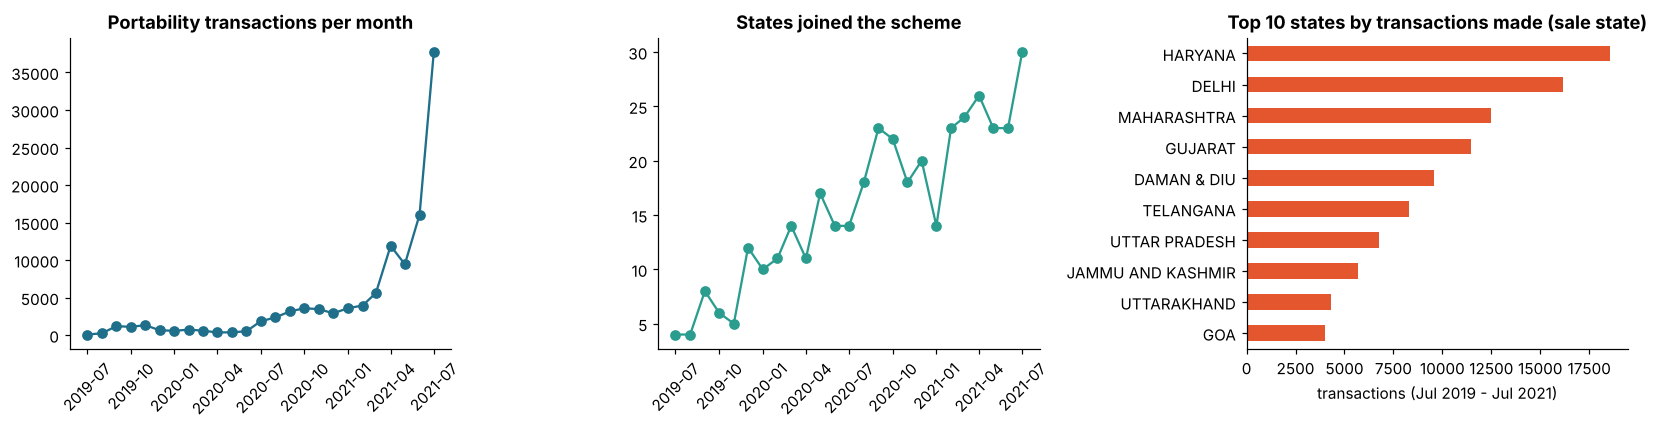

months: 25 | 2019-07-01 to 2021-07-01 | peak transactions: 37719 in Jul 2021
states joined: first month 4 -> last month 30
top sale states: {'HARYANA': 18553, 'DELHI': 16150, 'MAHARASHTRA': 12464}


In [37]:
pm = extra["12 PDS monthly national"].copy(); pm["date"] = pd.to_datetime(dict(year=pm.year, month=pm.month, day=1)); pm = pm.sort_values("date")
pf = extra["13 PDS state portability"].copy()
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(pm.date, pm.total_txn, "o-", color=C["main"]); ax[0].set_title("Portability transactions per month"); ax[0].tick_params(axis="x", rotation=45)
ax[1].plot(pm.date, pm.states_joined, "o-", color=C["good"]); ax[1].set_title("States joined the scheme"); ax[1].tick_params(axis="x", rotation=45)
top = pf.groupby("sale_state").transactions.sum().sort_values().tail(10)
top.plot.barh(ax=ax[2], color=C["accent"]); ax[2].set_title("Top 10 states by transactions made (sale state)"); ax[2].set_xlabel("transactions (Jul 2019 - Jul 2021)"); ax[2].set_ylabel("")
save(fig, "20_pds_snapshot")
print("months:", len(pm), "|", pm.date.min().date(), "to", pm.date.max().date(), "| peak transactions:", int(pm.total_txn.max()), "in", pm.loc[pm.total_txn.idxmax(),"date"].strftime("%b %Y"))
print("states joined: first month", int(pm.states_joined.iloc[0]), "-> last month", int(pm.states_joined.iloc[-1]))
print("top sale states:", top.sort_values(ascending=False).head(3).to_dict())